<a id="notebook-guide"></a>
# Reduced qubit hybrid hourly — main solution

**Question:** Can we shrink each hourly QAOA circuit while retaining valid 24-hour schedules and a small cost gap?

Run the setup, paired comparison and dispatch sections in order. The seed/shot sweep is a separate, more extensive benchmark near the end. Only plants legally fixed by minimum up/down rules are removed; coal is not fixed simply because it often runs. Dispatch and constraint checks remain classical.

1. [Method and setup](#reduced-hybrid-main)
2. [Recorded findings](#reduced-hybrid-findings)
3. [Commitment and dispatch](#dispatch)
4. [Seed and shot benchmark](#rq-seed-shot-sweeps)

This is a hybrid heuristic evaluated with ideal local simulation. Smaller circuits and a low cost gap do not establish quantum advantage.

[Main method](01_reduced_qubit_hourly.ipynb) · [Window selection](02_quantum_window_selection.ipynb) · [Solar + wind](03_solar_wind.ipynb) · [Other experiments](04_other_experiments.ipynb)

Use the **qBraid-SDK kernel** and run from this project directory. No other notebook needs to be run first. Existing outputs below were copied from the original starter; they are recorded results, not fresh executions of this split. The original `starter.ipynb` is preserved as an archive and is not a runtime dependency. End times are exclusive: **13:00–18:00 means hours 13, 14, 15, 16, 17**.


[Milestone audit](#milestone-audit): completed checks, primer, quantum-vs-random evidence and pending hardware.


<a id="reduced-hybrid-main"></a>
## MAIN SOLUTION — reduced qubit hybrid hourly method (5 and 10 plants)

**Run RQ 1 → RQ 5 below, in order.** Earlier experiment cells do not need to execute.
Use the qBraid-SDK kernel. Helpers are imported from `notebook_studies.py`; no notebook is read at runtime.

The workflow for each QAOA hour is:

**Operating history → forced on/off plants → exact QUBO substitution → smaller hourly circuit → local angle tuning and sampling → reconstruct all plant decisions → validate → next hour.**

The MILP handles the other hours with the operating history carried forward. The QAOA period is
**13:00–18:00, excluding hour 18**. This is five separate circuits, one per planning hour.

**Why reduce qubits?** A forced decision is already known, so a quantum circuit need not search over it.
Removing one such decision removes one qubit and its interactions. Statevector size scales as $2^q$:
13 to 11 qubits reduces its entries from 8,192 to 2,048. This can lower local simulation work and
future circuit gate requirements. It does not guarantee lower operating cost, fewer billed credits,
or a hardware speedup. We measure cost and resource savings separately.

**Fair comparison:** each fleet uses its own matching demand/reserve and MILP baseline. Within each fleet, we keep three slack bits, approximate hourly operating-cost model,
one QAOA layer, 200 samples, classical feasibility checks, and the MILP lookahead policy.
Fixing locks enforces those particular states exactly; the resulting QAOA sampling distribution can change.



### RQ 1 — Setup and experiment settings

Imports, fleet selection (`RQ_FLEETS = (5, 10)`), seeds, hourly period, shot count, and isolated shared study helpers. This cell does not run the benchmark. Keep the six seeds for comparison with the recorded findings.


In [ ]:
# RQ 1 — Setup and experiment settings
# ==================== REDUCED-QUBIT 5 AND 10 PLANT study ====================
# Compare the original hourly circuits with exact substitution of plants forced
# on/off by minimum operating times. QAOA still runs at every hour 13,14,15,16,17.
# [13:00,18:00) EXCLUDES hour 18. Include it with range(13,19).
# Local angle tuning AND local ideal sampling; no QPU/cloud jobs are submitted.
# Hardware benefits below are circuit-resource counts, not measured hardware speedups.
import ast as rq_ast
import json as rq_json
from pathlib import Path as rq_Path
from time import perf_counter as rq_clock
import numpy as rq_np
import matplotlib.pyplot as rq_plt

RQ_FLEETS = (5, 10)  # Each uses its own plants, demand/reserve, and MILP baseline.
RQ_SEEDS = (7, 8, 9, 17, 18, 19)
RQ_HOURS = tuple(range(13,18))
RQ_SHOTS = 200
RQ_FULL_DAY_CONTROL = True
RQ_MAX_QUBITS = 18  # Guard BEFORE state-space allocation; does not force legal locks.


from notebook_studies import study_context

def rq_helpers(fleet_count=10):
    # Isolated shared helpers; no cell lookup and no experiment runs on import.
    context = study_context(RQ_SHOTS=RQ_SHOTS, RQ_MAX_QUBITS=RQ_MAX_QUBITS)
    return context['rq_helpers'](fleet_count)


### RQ 2 — Exact QUBO reduction — core mathematics

`rq_substitute` removes forced variables while preserving their linear and constant contributions. This is the key implementation; deleting rows and columns alone would be incorrect.


In [ ]:
# RQ 2 — Exact QUBO reduction — core mathematics
# With x_fixed=v, free/fixed interactions become linear terms; fixed/fixed terms
# become an offset. No full statevector indices or probabilities are allocated.
def rq_substitute(Q, offset, fixed):
    from reduced_quantum_method import substitute
    return substitute(Q, offset, fixed)


### RQ 3 — Reduced allocation and correctness audit

`rq_adapt` fixes legally forced plant states before simulation and keeps probabilities compressed. The scheduler decodes only sampled outcomes; it allocates probabilities only for the reduced circuit. `rq_audit` checks all reduced-state energies on these small examples, separately from benchmark timing. Implementation: `reduced_quantum_method.py`.


In [ ]:
# RQ 3 — Hourly reduced circuit and correctness audit
# Circuit, state table and probability array all use the reduced qubit count.
# Decode only sampled outcomes, restoring forced plant bits into those rows.
def rq_adapt(ns, reduced):
    from reduced_quantum_method import adapt
    return adapt(ns, reduced)


def rq_audit(trace, full_bits=None):
    # full_bits is accepted for API compatibility; the audit uses reduced states.
    # Exhaustively compare energies only within the small restricted domain.
    from reduced_quantum_method import audit_reduction
    return audit_reduction(trace)


### RQ 4 — Define the paired comparison

Defines `run_reduced_plant_study`; no experiment runs yet. It compares MILP, original/reduced hourly hybrids, and original/reduced full-day QAOA using the same seeds for each fleet and separate MILP baselines. Invalid days are excluded from cost-gap averages and reported separately.


In [ ]:
# RQ 4 — Define the paired comparison
def run_reduced_plant_study(fleet_count=10):
    helper = rq_helpers(fleet_count)
    original_variant = f'original {fleet_count+3} qubits'
    ns = helper['nd_make_namespace']()
    stats = helper['nd_instrument'](ns)
    ref, art = helper['nd_one_run'](ns,stats,'FULL MILP',(),'milp',RQ_SEEDS[0],None,'reduction')
    assert ref['valid'] and ref['milp_domain_optimal']
    reference = ref['cost']
    print(f'REDUCED-QUBIT {fleet_count} PLANT study: MILP reference ${reference:,.2f}',flush=True)
    print(f'QAOA hours {list(RQ_HOURS)}; p=1, {RQ_SHOTS} shots, 3 slack bits; seeds {RQ_SEEDS}')
    print('Only genuine minimum-up/down locks are fixed; no MILP choices are used to fix free plants.')
    print('Full and reduced runs can develop different histories. Warm-start angles are retained.')
    print('Reduced circuits cannot violate a fixed lock. Other original fallbacks remain and are checked.')
    rows, artifacts, hourly_rows, traces = [], {}, [], {}
    # Primary result: hourly QAOA during 13..17, MILP for the other hours.
    # MILP still looks ahead through the remaining day; all that work is timed.
    # Full-day QAOA is a separate control to show what the time split contributes.
    scenarios = [('13:00–18:00',RQ_HOURS)]
    if RQ_FULL_DAY_CONTROL:
        scenarios.append(('FULL DAY',tuple(range(24))))
    for seed in RQ_SEEDS:
        # Repeat baseline as well so timing is not just a single cold-start observation.
        ns = helper['nd_make_namespace'](); stats=helper['nd_instrument'](ns)
        row,art=helper['nd_one_run'](ns,stats,'FULL MILP',(),'milp',seed,reference,'reduction')
        row.update(fleet=fleet_count,variant='MILP',min_qubits=0,max_qubits=0,mean_qubits=0,mean_rzz=0,
                   mean_statevector_entries=0,audit_s=0)
        rows.append(row);artifacts[('MILP','FULL MILP',seed)]=art
        for label, selected in scenarios:
            for reduced in (False,True):
                variant = 'fixed plants removed' if reduced else original_variant
                ns=helper['nd_make_namespace']()
                trace=rq_adapt(ns,reduced)
                stats=helper['nd_instrument'](ns)
                row,art=helper['nd_one_run'](ns,stats,label,selected,'qaoa',seed,reference,'reduction')
                row.update(fleet=fleet_count,variant=variant,
                    min_qubits=min((r['qubits'] for r in trace),default=0),
                    max_qubits=max((r['qubits'] for r in trace),default=0),
                    mean_qubits=float(rq_np.mean([r['qubits'] for r in trace])) if trace else 0,
                    mean_rzz=float(rq_np.mean([r['logical_rzz'] for r in trace])) if trace else 0,
                    mean_statevector_entries=float(rq_np.mean([r['statevector_entries'] for r in trace])) if trace else 0,
                    audit_s=rq_audit(trace,ns['INDEX_BITS']))
                assert len(trace)<=len(selected)
                for t,item in zip(selected,trace):
                    hourly_rows.append(dict(fleet=fleet_count,window=label,variant=variant,seed=seed,hour=t,
                        qubits=item['qubits'],forced_plants=item['forced'],logical_rzz=item['logical_rzz'],
                        statevector_entries=item['statevector_entries'],
                        forced_names=', '.join(f"{ns['names'][i]}={v}" for i,v in item['fixed'].items())))
                rows.append(row);artifacts[(variant,label,seed)]=art;traces[(variant,label,seed)]=trace
                gap=f"{row['gap_pct']:.4f}%" if row['valid'] else 'INVALID'
                print(f"seed {seed}, {label}, {variant}: gap {gap}, "
                      f"qubits {row['min_qubits']}–{row['max_qubits']}, total {row['total_s']:.2f}s",flush=True)
    summary=[]
    for label,variant in dict.fromkeys((r['window'],r['variant']) for r in rows):
        group=[r for r in rows if r['window']==label and r['variant']==variant]
        gaps=[r['gap_pct'] for r in group if r['valid']]
        summary.append(dict(fleet=fleet_count,window=label,variant=variant,runs=len(group),
            valid_days=sum(r['valid'] for r in group),
            mean_valid_gap_pct=float(rq_np.mean(gaps)) if gaps else None,
            worst_valid_gap_pct=max(gaps) if gaps else None,
            min_qubits=min(r['min_qubits'] for r in group),max_qubits=max(r['max_qubits'] for r in group),
            mean_qubits=float(rq_np.mean([r['mean_qubits'] for r in group])),
            mean_logical_rzz=float(rq_np.mean([r['mean_rzz'] for r in group])),
            mean_statevector_entries=float(rq_np.mean([r['mean_statevector_entries'] for r in group])),
            median_total_s=float(rq_np.median([r['total_s'] for r in group])),
            median_qaoa_s=float(rq_np.median([r['qaoa_s'] for r in group])),
            median_milp_s=float(rq_np.median([r['milp_s'] for r in group])),
            quantum_job_credits=0))
    print('\nCOST AND RESOURCE COMPARISON (invalid days excluded from gaps, not from timings)')
    helper['nd_table'](summary)
    print('\nPAIRED COST-GAP DIFFERENCE: reduced minus original; negative is better.')
    pairs=[]
    for label,selected in scenarios:
        for seed in RQ_SEEDS:
            a=next(r for r in rows if r['window']==label and r['seed']==seed and r['variant']==original_variant)
            b=next(r for r in rows if r['window']==label and r['seed']==seed and r['variant']=='fixed plants removed')
            pairs.append(dict(fleet=fleet_count,window=label,seed=seed,original_valid=a['valid'],reduced_valid=b['valid'],
                gap_change_percentage_points=b['gap_pct']-a['gap_pct'] if a['valid'] and b['valid'] else None,
                total_time_ratio=b['total_s']/a['total_s']))
    helper['nd_table'](pairs)
    print('\nPER-HOUR REDUCED CIRCUITS: 13:00–18:00 (all seeds; actual locks in each evolving history)')
    helper['nd_table']([r for r in hourly_rows if r['window']=='13:00–18:00' and r['variant']=='fixed plants removed'])
    fig,axes=rq_plt.subplots(1,2,figsize=(12,4))
    for seed in RQ_SEEDS:
        sub=[r for r in hourly_rows if r['window']=='13:00–18:00' and r['variant']=='fixed plants removed' and r['seed']==seed]
        axes[0].plot([r['hour'] for r in sub],[r['qubits'] for r in sub],'o-',label=f'seed {seed}')
    axes[0].axhline(fleet_count+3,color='black',linestyle='--',label='Original')
    axes[0].set(xlabel='Planning hour',ylabel='Qubits per circuit',title='Fixed-plant substitution',xticks=list(RQ_HOURS))
    axes[0].legend(fontsize=7)
    labels=[f"{r['window']}\n{r['variant']}" for r in summary]
    axes[1].bar(range(len(summary)),[r['mean_valid_gap_pct'] if r['mean_valid_gap_pct'] is not None else float('nan') for r in summary])
    axes[1].set_xticks(range(len(summary)),labels,rotation=25,ha='right',fontsize=8)
    axes[1].set(ylabel='Mean valid daily cost gap (%)',title=f'{fleet_count} plants: check valid-day counts in table')
    fig.suptitle(f'Reduced-qubit comparison: {fleet_count} plants')
    fig.tight_layout();rq_plt.show()
    print('All substitutions passed exhaustive energy-equivalence checks, including offsets.')
    print('Logical RZZ counts are before hardware transpilation/routing; statevector entries are not runtime predictions.')
    print('Total timing includes substitution, sampled decoding, MILP lookahead, local tuning and scheduling checks.')
    print('The extra exhaustive substitution audit is separate: total audit seconds =',sum(r['audit_s'] for r in rows))
    print('No actual hardware sampling/noise was tested. Local ideal simulation job credits = 0.')
    print('Fixing locks changes the variational search and enforces those locks exactly; lower qubits do not guarantee lower cost.')
    print('Three slack bits and the original approximate hourly objective remain; this does not fix their modeling limitations.')
    return dict(fleet=fleet_count,reference_cost=reference,summary=summary,runs=rows,hourly=hourly_rows,
                paired=pairs,artifacts=artifacts,traces=traces,
                settings=dict(fleet=fleet_count,seeds=RQ_SEEDS,hours=RQ_HOURS,shots=RQ_SHOTS,slack=3,layers=1))




### RQ 5 — RUN THE STUDY — results and plots

Run this cell after RQ 1–RQ 4. It executes the 60 comparisons (30 per fleet) and creates `reduced_plant_studies[5]` and `reduced_plant_studies[10]`. Saved tables and plots below are from the completed six-seed comparison for both fleets. Rerunning may take several minutes; runtime depends on shared-instance load. No cloud jobs are submitted.


In [ ]:
# RQ 5 — RUN BOTH FLEETS — results and plots
# Five plants use plants.csv/demand.csv; ten use plants10.csv/demand10.csv.
# Each fleet gets its own proven MILP reference and the same six sampling seeds.
# Default: 30 runs per fleet, 60 total; no cloud jobs or extra project files.
if not RQ_FLEETS or len(set(RQ_FLEETS)) != len(RQ_FLEETS):
    raise ValueError('Choose a nonempty set of distinct fleets, e.g. (5,10).')
reduced_plant_studies = {
    fleet: run_reduced_plant_study(fleet_count=fleet) for fleet in RQ_FLEETS
}
# Alias for inspecting the ten-plant results.
reduced_plant_study = reduced_plant_studies.get(10, next(iter(reduced_plant_studies.values())))
print('\nSIDE-BY-SIDE FLEET COMPARISON: gaps use each fleet\'s own MILP optimum.')
rq_helpers()['nd_table']([
    row for study in reduced_plant_studies.values() for row in study['summary']
])
# Detailed five-plant results: reduced_plant_studies[5]
# Detailed ten-plant results:  reduced_plant_studies[10]
# ================== End REDUCED-QUBIT 5 AND 10 PLANT study ==================


<a id="reduced-hybrid-findings"></a>
### Recorded findings — five and ten plants, six seeds each

**Historical measurements:** these tables precede the allocation fix. The twelve reduced gross-demand window schedules were reproduced exactly after the fix; old timings include the removed compatibility arrays and exhaustive hourly diagnostics.

The recorded RQ 5 study contains **60 comparisons**, 30 for each fleet. Each uses its matching demand/reserve
and its own MILP optimum: **$327,924.49 for five plants**, **$602,139.47 for ten plants**.
Settings: hours 13–17 (13:00–18:00, excluding hour 18), 200 shots, one QAOA layer,
three slack bits; seeds 7, 8, 9, 17, 18, 19. Rerunning RQ 5 produces fresh timing measurements.

| Plants | Method | Valid days | Mean valid cost gap | Qubits per circuit | Median total runtime |
|---|---|---:|---:|---:|---:|
| 5 | Full MILP | 6/6 | 0.000% | — | 0.08 s |
| 5 | Original 13:00–18:00 hybrid | 6/6 | 0.000% | 8 | 2.03 s |
| 5 | Reduced 13:00–18:00 hybrid | 6/6 | 0.000% | 7–8 | 1.80 s |
| 5 | Original full-day QAOA | 6/6 | 7.062% | 8 | 6.75 s |
| 5 | Reduced full-day QAOA | 6/6 | 7.062% | 5–8 | 6.28 s |
| 10 | Full MILP | 6/6 | 0.000% | — | 0.08 s |
| 10 | Original 13:00–18:00 hybrid | 6/6 | 0.107% | 13 | 3.40 s |
| 10 | Reduced 13:00–18:00 hybrid | 6/6 | 0.079% | 11–13 | 1.96 s |
| 10 | Original full-day QAOA | 5/6 | 14.002% | 13 | 10.51 s |
| 10 | Reduced full-day QAOA | 5/6 | 10.277% | 7–13 | 6.68 s |

**What this supports:**

- Both afternoon hybrids were valid in **6/6 runs for each fleet**.
- For five plants, both hybrids reached the MILP cost in all six seeds. Reduction made some
  circuits smaller (7–8 instead of 8 qubits), with no cost improvement needed.
- For ten plants, the reduced hybrid averaged **0.079%** above MILP versus **0.107%** originally.
  It improved cost in two seeds, tied in three, and worsened in one. Its 11–13 qubits are not
  a guarantee that every hourly circuit shrinks; 29 of 30 did in this experiment.
- Full-day QAOA remains a different comparison: the ten-plant versions each had one invalid run.
  Invalid runs are reported and excluded from cost-gap averages, not silently accepted.
- All substitutions passed exhaustive energy-equivalence checks. Only plant states forced by
  minimum operating times are eliminated; free plant decisions are not filled in from the optimum.
- MILP remains the reference and fastest method here. Circuit counts are logical counts before
  hardware routing; local simulation does not establish QPU speedup or noise performance.
- Quantum-job credits spent: **zero**. The unchanged three-slack-bit encoding and approximate
  hourly objective remain limitations. Small seed samples and one demand day limit generalization.

**Run or inspect:** use `RQ_FLEETS = (5, 10)` in RQ 1 and execute RQ 1–RQ 5.
`reduced_plant_studies[5]` and `[10]` each contain `summary`, `runs`, `hourly`, `paired`,
`artifacts` (schedules and checker results), and `traces` (QUBOs, mappings, angles).
`reduced_plant_study` remains an alias for the ten-plant results.

[Back to notebook guide](#notebook-guide)


<a id="dispatch"></a>
## Commitment and dispatch comparison — optional results viewer

This cell displays results from **your reduced qubit hybrid hourly method**; it does not define a different scheduling algorithm. It compares each plant’s hourly on/off state and MW output with full-day MILP, and shows which qubits were removed.

Run RQ 1–RQ 4 first. If RQ 5 has run, this viewer reuses its schedules. Otherwise it runs one MILP day and one reduced-hybrid day using the same shared implementation. The viewer is optional: the method and benchmark do not depend on it.

Use `DISPATCH_FLEET` and `DISPATCH_SEED` below to choose which result to display.


In [ ]:
# COMMITMENT AND DISPATCH COMPARISON
# Optional results viewer for the reduced qubit hybrid hourly method.
# This displays the same algorithm used in RQ 1–RQ 5; it is not a separate method.
# Which plants are ON / OFF at each hour of the day, for:
#   (a) the full MILP (the optimal reference), and
#   (b) the reduced-qubit hybrid: QAOA for hours 13-17 (13:00-18:00), MILP for every other hour.
# Needs RQ 1 -> RQ 4 run first. If RQ 5 has already run, its saved schedules are reused;
# otherwise this cell runs ONE MILP day and ONE reduced-hybrid day (a few seconds, local only,
# no quantum jobs / credits).
import html as dispatch_html
from IPython.display import HTML as dispatch_HTML, display as dispatch_display

DISPATCH_FLEET = 10      # 10-plant fleet (plants10.csv / demand10.csv); 5 also works
DISPATCH_SEED = 7        # any of RQ_SEEDS = (7, 8, 9, 17, 18, 19)
DISPATCH_LABEL, DISPATCH_VARIANT = '13:00–18:00', 'fixed plants removed'

dispatch_helper = rq_helpers(DISPATCH_FLEET)
dispatch_ns = dispatch_helper['nd_make_namespace']()
dispatch_names = dispatch_ns['names']
dispatch_study = globals().get('reduced_plant_studies', {}).get(DISPATCH_FLEET)

if dispatch_study is not None and (DISPATCH_VARIANT, DISPATCH_LABEL, DISPATCH_SEED) in dispatch_study['artifacts']:
    print(f'Using saved RQ 5 results: {DISPATCH_FLEET} plants, seed {DISPATCH_SEED}')
    dispatch_milp = dispatch_study['artifacts'][('MILP', 'FULL MILP', DISPATCH_SEED)]
    dispatch_hyb = dispatch_study['artifacts'][(DISPATCH_VARIANT, DISPATCH_LABEL, DISPATCH_SEED)]
    dispatch_trace = dispatch_study['traces'][(DISPATCH_VARIANT, DISPATCH_LABEL, DISPATCH_SEED)]
else:
    print(f'Running one MILP day and one reduced-hybrid day: {DISPATCH_FLEET} plants, seed {DISPATCH_SEED}')
    dispatch_stats = dispatch_helper['nd_instrument'](dispatch_ns)
    _, dispatch_milp = dispatch_helper['nd_one_run'](dispatch_ns, dispatch_stats, 'FULL MILP', (), 'milp', DISPATCH_SEED, None, 'dispatch_comparison')
    dispatch_ref = dispatch_milp['result']['total_cost']
    dispatch_ns = dispatch_helper['nd_make_namespace']()
    dispatch_trace = rq_adapt(dispatch_ns, reduced=True)
    dispatch_stats = dispatch_helper['nd_instrument'](dispatch_ns)
    _, dispatch_hyb = dispatch_helper['nd_one_run'](dispatch_ns, dispatch_stats, DISPATCH_LABEL, RQ_HOURS, 'qaoa', DISPATCH_SEED, dispatch_ref, 'dispatch_comparison')

dispatch_S_milp = rq_np.asarray(dispatch_milp['schedule']).astype(int)      # hours x plants, 1 = ON
dispatch_S_hyb = rq_np.asarray(dispatch_hyb['schedule']).astype(int)
dispatch_MW_hyb = dispatch_hyb['result']['dispatch']                       # MW each plant produces
dispatch_per_hour = dict(zip(RQ_HOURS, dispatch_trace))                   # QAOA hours -> circuit info

# ---------- 1. Hour-by-hour ON/OFF table for the reduced hybrid ----------
dispatch_rows = []
for t in range(len(dispatch_S_hyb)):
    row = {'hour': f'{t:02}:00', 'decided by': 'QAOA (reduced)' if t in dispatch_per_hour else 'MILP'}
    for i, name in enumerate(dispatch_names):
        row[name] = f'ON {dispatch_MW_hyb[t, i]:.0f} MW' if dispatch_S_hyb[t, i] else 'off'
    info = dispatch_per_hour.get(t)
    row['qubits'] = info['qubits'] if info else '—'
    row['locked (removed from circuit)'] = (', '.join(f"{dispatch_names[i]}={'ON' if v else 'off'}"
                                            for i, v in info['fixed'].items()) or 'none') if info else '—'
    row['plants ON'] = int(dispatch_S_hyb[t].sum())
    row['same as MILP?'] = 'yes' if (dispatch_S_hyb[t] == dispatch_S_milp[t]).all() else 'NO: ' + ', '.join(
        f"{dispatch_names[i]} {'ON' if dispatch_S_hyb[t, i] else 'off'} (MILP {'ON' if dispatch_S_milp[t, i] else 'off'})"
        for i in rq_np.flatnonzero(dispatch_S_hyb[t] != dispatch_S_milp[t]))
    dispatch_rows.append(row)

def dispatch_color(value):
    value = str(value)
    if value.startswith('ON'):
        return 'background:#2e7d32;color:white'
    if value == 'off':
        return 'background:#e0e0e0;color:#666'
    if value.startswith('NO'):
        return 'background:#ffcdd2;color:black'
    return ''

print(f"\nREDUCED-QUBIT HYBRID, {DISPATCH_FLEET} plants, seed {DISPATCH_SEED}: "
      f"cost ${dispatch_hyb['result']['total_cost']:,.2f}, valid={dispatch_hyb['result']['valid']}, "
      f"gap vs MILP {dispatch_hyb['result']['gap_pct'] if dispatch_hyb['result']['gap_pct'] is not None else float('nan'):.4f}%")
print(f"FULL MILP: cost ${dispatch_milp['result']['total_cost']:,.2f}")
print('Bold rows = QAOA hours (13-17). Green = plant ON (MW produced), grey = off, red = differs from MILP.')
dispatch_cols = list(dispatch_rows[0])
dispatch_html_rows = ''.join(
    ('<tr style="font-weight:bold;outline:2px solid orange">' if r['decided by'].startswith('QAOA') else '<tr>')
    + ''.join(f'<td style="padding:2px 6px;white-space:nowrap;{dispatch_color(r[c])}">{dispatch_html.escape(str(r[c]))}</td>'
              for c in dispatch_cols) + '</tr>' for r in dispatch_rows)
dispatch_display(dispatch_HTML('<table style="border-collapse:collapse;font-size:12px"><tr>'
    + ''.join(f'<th style="padding:2px 6px">{dispatch_html.escape(c)}</th>' for c in dispatch_cols)
    + '</tr>' + dispatch_html_rows + '</table>'))

# ---------- 2. Picture: MILP vs reduced hybrid, side by side ----------
fig, axes = rq_plt.subplots(1, 3, figsize=(16, 5), sharey=True,
                            gridspec_kw=dict(width_ratios=[1, 1, 1]))
dispatch_diff = dispatch_S_hyb - dispatch_S_milp
panels = [(dispatch_S_milp, 'Full MILP', 'Greens', 0, 1),
          (dispatch_S_hyb, 'Reduced hybrid (QAOA 13-17, MILP rest)', 'Greens', 0, 1),
          (dispatch_diff, 'Hybrid minus MILP (+1 extra ON, -1 missing)', 'bwr', -1, 1)]
for ax, (data, title, cmap, lo, hi) in zip(axes, panels):
    ax.imshow(data, aspect='auto', cmap=cmap, vmin=lo, vmax=hi, interpolation='nearest')
    ax.axhspan(min(RQ_HOURS) - 0.5, max(RQ_HOURS) + 0.5, fill=False, edgecolor='orange', lw=2.5)
    ax.set_xticks(range(len(dispatch_names)), dispatch_names, rotation=60, ha='right', fontsize=8)
    ax.set_title(title, fontsize=10)
    for t in range(data.shape[0]):
        for i in range(data.shape[1]):
            if data is dispatch_diff and data[t, i]:
                ax.text(i, t, '+' if data[t, i] > 0 else '−', ha='center', va='center', fontsize=9)
axes[0].set_yticks(range(len(dispatch_S_hyb)), [f'{t:02}:00' for t in range(len(dispatch_S_hyb))], fontsize=7)
axes[0].set_ylabel('Hour of day (orange box = QAOA hours)')
fig.suptitle(f'{DISPATCH_FLEET} plants, seed {DISPATCH_SEED}: who is ON (dark green) at each hour')
fig.tight_layout(); rq_plt.show()

# ---------- 3. Short text summary of the QAOA hours ----------
print('\nQAOA HOURS IN DETAIL')
for t, info in dispatch_per_hour.items():
    on = [dispatch_names[i] for i in range(len(dispatch_names)) if dispatch_S_hyb[t, i]]
    off = [dispatch_names[i] for i in range(len(dispatch_names)) if not dispatch_S_hyb[t, i]]
    locked = [dispatch_names[i] for i in info['fixed']]
    locked_txt = [f"{dispatch_names[i]}={'ON' if v else 'off'}" for i, v in info['fixed'].items()]
    chosen = [n for n in on if n not in locked]
    print(f"{t:02}:00  {info['qubits']:>2} qubits | ON: {', '.join(on)}\n"
          f"        OFF: {', '.join(off) or 'none'}\n"
          f"        locked by min up/down (not in circuit): {', '.join(locked_txt) or 'none'}"
          f" | ON by QAOA's own choice: {', '.join(chosen) or 'none'}")

# ---------- 4. If RQ 5 ran: where does each seed differ from MILP? ----------
if dispatch_study is not None:
    print('\nALL SEEDS: hours where the reduced hybrid differs from MILP')
    for s in RQ_SEEDS:
        h = rq_np.asarray(dispatch_study['artifacts'][(DISPATCH_VARIANT, DISPATCH_LABEL, s)]['schedule']).astype(int)
        m = rq_np.asarray(dispatch_study['artifacts'][('MILP', 'FULL MILP', s)]['schedule']).astype(int)
        bad = [f"{t:02}:00 ({', '.join(dispatch_names[i] for i in rq_np.flatnonzero(h[t] != m[t]))})"
               for t in range(len(h)) if (h[t] != m[t]).any()]
        print(f"  seed {s}: {'; '.join(bad) if bad else 'identical to MILP every hour'}")

<a id="rq-seed-shot-sweeps"></a>
## MAIN STUDY — Reduced Qubit Hybrid Hourly: seed and shot sweeps

**Run the single code cell below with the qBraid-SDK kernel.** It is standalone; RQ 1–RQ 5 and all earlier cells are optional background. This study uses the supplied **gross-demand five- and ten-plant fleets**, with quantum hours **13, 14, 15, 16, 17**. It does not use solar/wind or multi-hour refinement. All quantum execution is **ideal local statevector simulation**; noise models, cloud simulators and real hardware are deferred.

Default settings: **10 seeds (101–110) × 6 shot budgets (5, 10, 20, 50, 100, 200) × 3 methods × 2 fleets = 360 sampled trials**, plus one deterministic exact-hourly reference per fleet. Methods are reduced QAOA, unreduced QAOA, and uniform random proposals obeying the same minimum-up/down restrictions. The exact-hourly control enumerates allowed local plant patterns; it is a separate classical comparator, not a full-day optimizer or a repair step.

Every sampled method builds a fresh full day and selects only observed feasible candidates. MILP constructs the surrounding hours, including initial full-day lookahead; a separately certified full-day MILP supplies the cost-gap denominator. Failures remain in the attempted-run counts and are never repaired or retried. Gap statistics are conditional on a valid day, so read them alongside the valid-day and target-success plots. The predeclared target is **valid and within 0.1% of MILP**; it does not influence candidate selection.

**What shots and seeds mean:** shots are final samples **per quantum hour**. Circuit angles are trained using deterministic exact statevector expectations, with fresh training in each trial. Seeds change measurement draws; later circuit inputs can change when earlier decisions change. These are repeated trials on two fixed datasets, not ten independent fleet/demand instances. Training work, MILP calls and total trial time are recorded. A reduced circuit and a softly constrained unreduced circuit need not have identical sampling distributions.

Results are checkpointed after each trial in a new `results/hourly_seed_shot_sweeps/<timestamp>/` folder. The completed run contains raw schedules, simulated measurement counts, angles, circuit traces, failures, software/source hashes, `summary.csv`, `paired.csv`, and PNG/PDF plots. Timing includes construction, training, sampling and scoring; the separately computed reference and development audits are reported separately. No result here is a measured hardware speedup.


IDEAL LOCAL SIMULATION — gross-demand hourly hybrid; no refinement or provider calls.


Fresh angle training per trial. Failed trials stay in the denominator. Results: /home/jovyan/tn-quantum-hackathon/3-tva-plant-scheduling/results/hourly_seed_shot_sweeps/20261115T060515020567Z



5 plants — certified MILP baseline $327,924.49


  shots=  5, seed=101: reduced_qaoa: 1.9816%; unreduced_qaoa: 2.6456%; random_locked: FAILED


  shots=  5, seed=102: unreduced_qaoa: 1.8235%; random_locked: FAILED; reduced_qaoa: 0.0000%


  shots=  5, seed=103: random_locked: FAILED; reduced_qaoa: 0.6641%; unreduced_qaoa: 1.3678%


... (116 outputs left out)

  shots=200, seed=109: random_locked: 0.0101%; reduced_qaoa: 0.0101%; unreduced_qaoa: 0.0101%


  shots=200, seed=110: reduced_qaoa: 0.0101%; unreduced_qaoa: 0.0101%; random_locked: 2.2263%



Completed 362 trials in 404.0s. All returned schedules and sampled selections checked.


Plants,Method,Shots/hour,Valid/attempted,Mean valid gap %,Worst valid gap %,Valid & gap ≤ 0.1%,Median total s,Max qubits
5,Exact hourly,all local patterns,1/1,0.0000,0.0000,1/1,0.087,0
5,Reduced QAOA,5,10/10,1.5742,2.6351,1/10,0.767,8
5,Unreduced QAOA,5,7/10,2.1032,3.1912,0/10,0.887,8
5,"Random, same locks",5,3/10,3.3010,3.7077,0/10,0.062,0
5,Unreduced QAOA,10,7/10,1.5909,2.4875,0/10,0.850,8
5,"Random, same locks",10,5/10,2.7653,3.3097,0/10,0.073,0
5,Reduced QAOA,10,9/10,1.2081,2.6351,1/10,0.791,8
5,"Random, same locks",20,10/10,1.6875,2.5272,1/10,0.120,0
5,Reduced QAOA,20,10/10,0.1402,0.6641,6/10,1.177,8
5,Unreduced QAOA,20,10/10,0.2522,1.1198,5/10,1.299,8


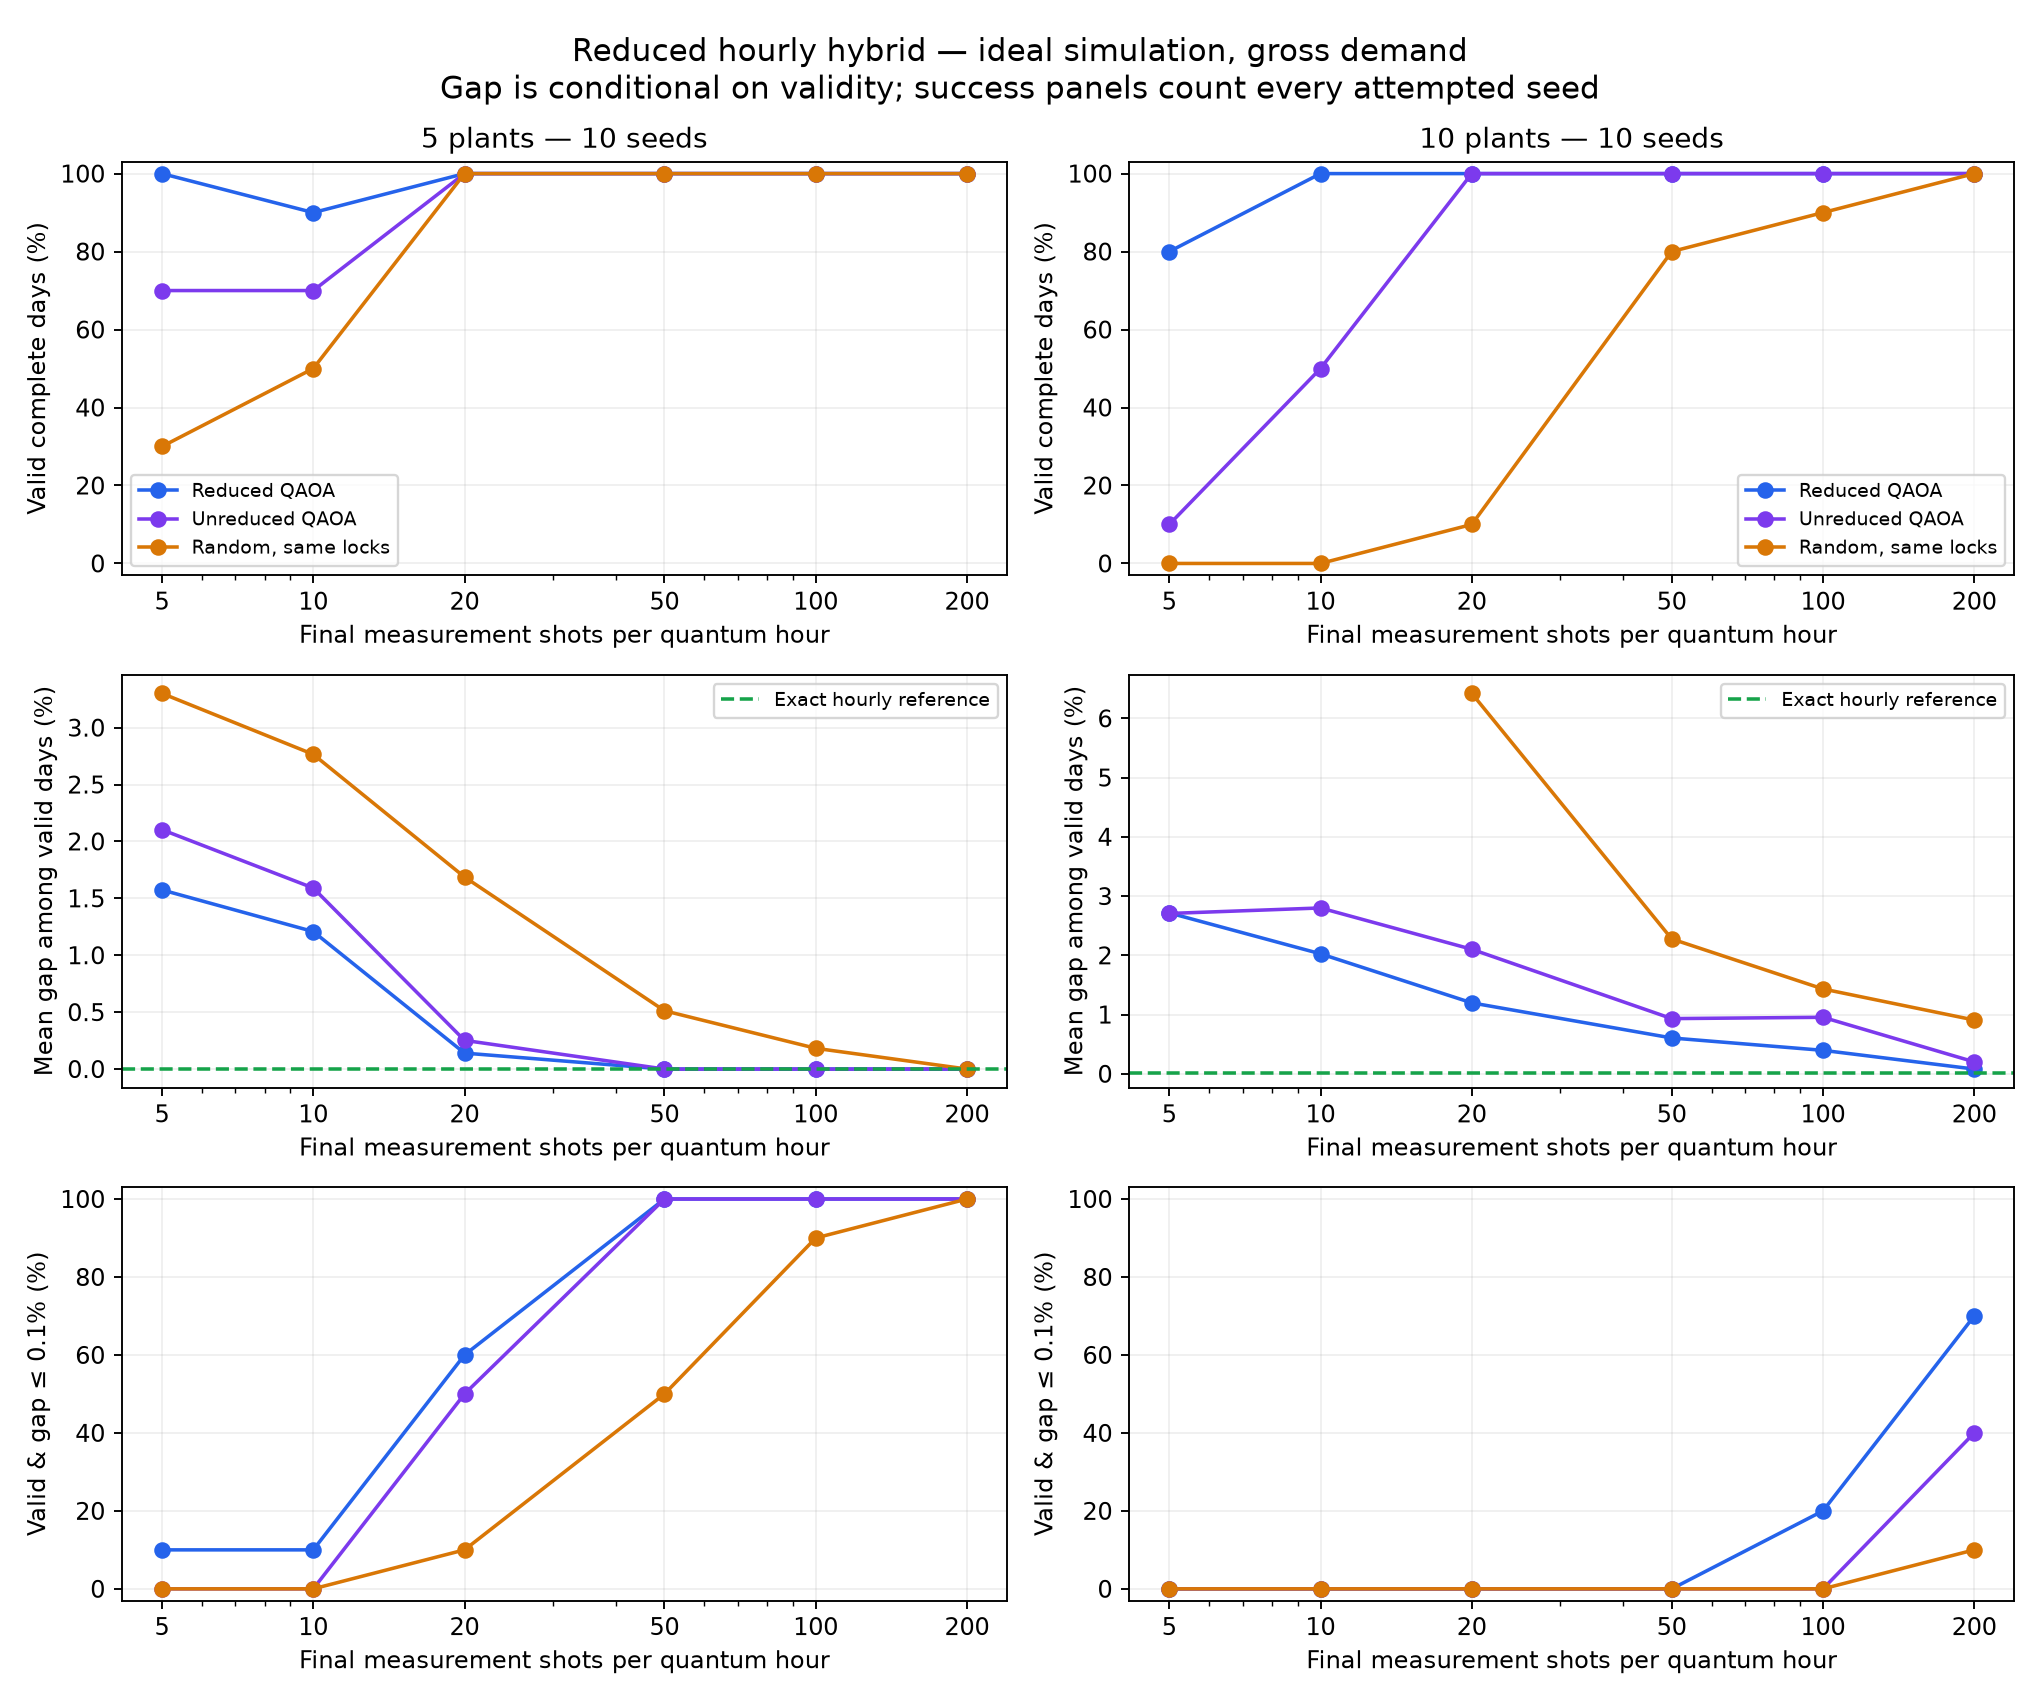

Gap baseline: matching certified full-day MILP. Exact hourly is a separate greedy classical reference.
QAOA and random select only sampled candidates. Failure means no valid day; no fallback or rerun.
Shots vary final draws, not angle-training shots. Exact-expectation training is timed and counted.
MILP constructs other hours, including initial full-day lookahead. This is not a MILP-free solver.
Seeds vary draws on the same fixed datasets, not independent demand instances. Confidence intervals are in summary.csv.
Reduced/unreduced circuits can sample differently despite exact energy substitution; no identical-distribution claim.
Saved traces, summaries, paired comparisons, versions/hashes, PNG and PDF: /home/jovyan/tn-quantum-hackathon/3-tva-plant-scheduling/results/hourly_seed_shot_sweeps/20261115T060515020567Z


In [ ]:
# MAIN STUDY — Reduced Qubit Hybrid Hourly: seed and shot sweeps
# Standalone: qBraid-SDK kernel. Run this cell, not the entire notebook.
# Ideal LOCAL simulation only; no refinement, renewables, noise model or provider calls.
from pathlib import Path
import sys, importlib

sweep_candidates = [Path.cwd(), Path.cwd()/'3-tva-plant-scheduling',
                    Path.cwd().parent/'3-tva-plant-scheduling']
sweep_method_dir = next(p for p in sweep_candidates if (p/'hourly_seed_shot_sweep.py').exists())
if str(sweep_method_dir) not in sys.path: sys.path.insert(0, str(sweep_method_dir))
import hourly_seed_shot_sweep as hourly_sweep
importlib.reload(hourly_sweep)

SWEEP_FLEETS = (5, 10)
SWEEP_SEEDS = tuple(range(101, 111))  # 10 fixed seeds; final sampling, not random training restarts
SWEEP_SHOTS = (5, 10, 20, 50, 100, 200)  # final shots PER quantum hour; training is separate
SWEEP_HOURS = tuple(range(13, 18))  # 13,14,15,16,17; other hours use MILP with day lookahead
SWEEP_MAX_QUBITS = 18  # allocation guard, not permission to fix extra plant decisions
SWEEP_TARGET_GAP_PCT = 0.1  # predeclared reporting target; never used to select a schedule

# Default: 360 sampled trials + 2 deterministic exact-hourly references.
# Each trial trains fresh p=1 circuits and builds its own day. Expect several minutes.
# A failed trial stays failed: no unsampled fallback, no retry-until-success.
# Every run creates a new folder and checkpoints each trial in runs.jsonl.
hourly_sweep_results = hourly_sweep.run_sweep(
    fleets=SWEEP_FLEETS, seeds=SWEEP_SEEDS, shots=SWEEP_SHOTS,
    quantum_hours=SWEEP_HOURS, max_qubits=SWEEP_MAX_QUBITS,
    layers=1, target_gap_pct=SWEEP_TARGET_GAP_PCT,
)
hourly_sweep_summary, hourly_sweep_pairs = hourly_sweep.display_sweep(hourly_sweep_results)
# Access paired comparisons in hourly_sweep_pairs or saved paired.csv.
# Inspect failures in runs.jsonl/results.json; summary.csv always retains their denominators.


<a id="milestone-audit"></a>
## Milestone audit — what is actually complete

This section is independent of the long studies above. Run its local audit and evidence cells from a fresh qBraid-SDK kernel. The compact record is `results/milestone_audit.json`. No cell submits hardware by default.

| Milestone | Status and evidence |
|---|---|
| 1 — Six-hour hand schedule | Completed; valid schedule and cost rechecked below. Demand plots and original schedule are also in notebook 04. |
| 2 — MILP and cheapest-first | Completed; baseline and rule implemented. The simple rule breaks a minimum-up constraint, so its cost is **not** a valid competitive solution. |
| 3 — QUBO and primer | Completed locally: one-hour “Match!” plus the 24 conditional checks below. The six-node [primer](qaoa_primer.ipynb) contains completed cost-layer/optimizer code, executed outputs, an independent random comparison, and the Max-Cut-to-plant explanation. |
| 4 — Full-day QAOA vs random | Completed: 50 required trials, 5/10/20/50/200 shots × five seeds × two samplers. Additional reduced-hourly study: 360 sampled trials plus two exact controls, with failures retained. |
| 5 — Noisy simulator and real hardware | Noisy tuning and independent noisy readout completed. **The warm-start Rigetti QPU experiment is complete**; see the hardware results below. The written milestone specifies IonQ, so Rigetti is a device substitution. These IonQ simulator results are separate from that real-hardware experiment. The circuit, counts, job IDs, price estimate, and pending submission cell are below. |
| 6 — Presentation | User-managed. No PowerPoint or slide outline was created or edited. Rehearsal and presentation readiness cannot be certified by this code audit. |

**Scope:** default scheduling uses linear dispatch, reserve and minimum up/down constraints, without ramp constraints. The hourly QUBO objective is an approximation. Passing the selected conditional checks does not prove it matches economic dispatch for every dataset or solves the full day optimally.


In [1]:
# LOCAL AUDIT — same supplied model and original algorithms, no remote jobs.
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from check import solve_milp, check_schedule, check_hour
from notebook_studies import make_legacy_namespace

milestone_ns = make_legacy_namespace(5)
milestone_plants = milestone_ns['plants']
milestone_demand, milestone_reserve = milestone_ns['demand'], milestone_ns['reserve']
milestone_hand = np.array([[1,0,0,0,0]]*5 + [[1,0,0,0,1]])
print('MILESTONE 1 — supplied six-hour hand schedule')
milestone_hand_check = check_schedule(milestone_plants, milestone_demand[:6],
                                    milestone_reserve[:6], milestone_hand)
assert milestone_hand_check['valid']

milestone_cost, milestone_schedule, milestone_dispatch, milestone_milp_seconds = solve_milp(
    milestone_plants, milestone_demand, milestone_reserve)
print('\nMILESTONE 2 — MILP baseline')
milestone_reference = check_schedule(milestone_plants, milestone_demand, milestone_reserve,
                                     milestone_schedule, milp_cost=milestone_cost)
assert milestone_reference['valid']
def milestone_cheapest_first(plants, demand, reserve):
    schedule = np.zeros((len(demand), len(plants)), dtype=int)

    # Rank plants by cost per MWh at full output.
    costs = [
        p["marginal_cost_per_mwh"]
        + p["no_load_cost_per_h"] / p["pmax_mw"]
        for p in plants
    ]
    order = np.argsort(costs)

    # Turn plants on in that order until capacity is sufficient.
    for t in range(len(demand)):
        capacity = 0.0
        required = demand[t] + reserve[t]

        for i in order:
            if capacity >= required:
                break

            schedule[t, i] = 1
            capacity += plants[i]["pmax_mw"]

    return schedule

print('\nOriginal cheapest-first rule (violations are reported, not hidden):')
milestone_rule = check_schedule(milestone_plants, milestone_demand, milestone_reserve,
    milestone_cheapest_first(milestone_plants, milestone_demand, milestone_reserve),
    milp_cost=milestone_cost)

print('\nMILESTONE 3 — QUBO minimum compared with exact hourly economic cost')
milestone_matches = []
for t in range(24):
    previous = milestone_schedule[t-1] if t else [p['on_at_start'] for p in milestone_plants]
    Q, offset = milestone_ns['build_qubo'](milestone_plants, milestone_demand[t],
                                         milestone_reserve[t], previous)
    energies = milestone_ns['all_energies'](Q, offset)
    bits = milestone_ns['INDEX_BITS'][int(np.argmin(energies))]
    match = check_hour(milestone_plants, milestone_demand[t], milestone_reserve[t],
                       bits[:5], was_on=previous, verbose=(t==12))
    milestone_matches.append(bool(match['matches_best']))
assert all(milestone_matches)
print(f'Matches: {sum(milestone_matches)}/24, conditional on the MILP previous-hour state.')
print('This does not prove that the greedy sequence is the optimal full-day schedule.')

milestone_record_path = Path('results/milestone_audit.json')
milestone_record = json.loads(milestone_record_path.read_text())
required = {(method,shots,seed) for method in ('qaoa','random')
            for shots in (5,10,20,50,200) for seed in range(5)}
actual = [(r['sampler'],int(r['shots']),int(r['seed']))
          for r in milestone_record['original_full_day_runs']]
assert len(actual)==50 and set(actual)==required
assert milestone_record['sweep_validation']['all_checks_passed']
print('\nMILESTONE 4 — all 50 required full-day sampler/shot/seed combinations are recorded.')
print('Reduced-hourly study: 362 total trials; 295 valid returned schedules, 67 failed trials.')

milestone_record['local_checks'] = dict(hand_valid=milestone_hand_check['valid'],
    hand_cost=milestone_hand_check['total_cost'], milp_cost=milestone_cost,
    cheapest_first_valid=milestone_rule['valid'], cheapest_first_cost=milestone_rule['total_cost'],
    cheapest_first_violations=milestone_rule['violations'], qubo_matches=sum(milestone_matches),
    original_required_trials=50)
milestone_record_path.write_text(json.dumps(milestone_record,indent=2)+'\n')


MILESTONE 1 — supplied six-hour hand schedule
Total cost: $44,555  (startups $130, no-load $3,970, energy $40,455)
Valid: every hour meets demand and reserve; no min up/down rule is broken.

MILESTONE 2 — MILP baseline
Total cost: $327,924  (startups $32,930, no-load $20,178, energy $274,816)
MILP optimum: $327,924   gap: +0.00%
Valid: every hour meets demand and reserve; no min up/down rule is broken.

Original cheapest-first rule (violations are reported, not hidden):
Total cost: $330,594  (startups $37,950, no-load $20,288, energy $272,356)
MILP optimum: $327,924   gap: +0.81%
NOT valid: 1 rule(s) broken
  hour  plant      rule             detail
    16  PEAKER_B   min up broken    turned off after 2 h on (needs 3)

MILESTONE 3 — QUBO minimum compared with exact hourly economic cost
Your choice: COAL+GAS_CC+OIL  ->  valid, cost $18,810
Match!
Matches: 24/24, conditional on the MILP previous-hour state.
This does not prove that the greedy sequence is the optimal full-day schedule.

M

106206

## What does QAOA contribute during the selected hours?

QAOA changes the distribution of sampled on/off candidates. The relevant evidence is the **paired comparison against random sampling in the same hourly hybrid**, not the overall gap to MILP alone.

At 200 final shots per selected hour, the ten-plant study found mean gaps of **0.0804% for reduced QAOA** and **0.9078% for random sampling**, both 10/10 valid. QAOA had lower cost in nine paired seeds and tied in one. Five plants at 200 shots tied at zero gap. At lower shot budgets, the valid-day counts matter as well as cost.

This is evidence of useful sampling relative to that random control on this dataset. **It is not a computational quantum advantage:** classical exact hourly search achieved a 0.0101% ten-plant gap in about 0.192 seconds, versus about 1.764 seconds for reduced QAOA; full-day MILP is the zero-gap reference. QAOA also used hundreds of exact-statevector evaluations during tuning. A 200-shot final budget is not its total computation budget. Ten seeds and one forecast day do not establish general superiority.


Plants,Method,Valid,Mean gap,Median seconds
5,random_locked,10/10,0.0000%,0.075
5,reduced_qaoa,10/10,0.0000%,0.789
10,reduced_qaoa,10/10,0.0804%,1.764
10,random_locked,10/10,0.9078%,0.140


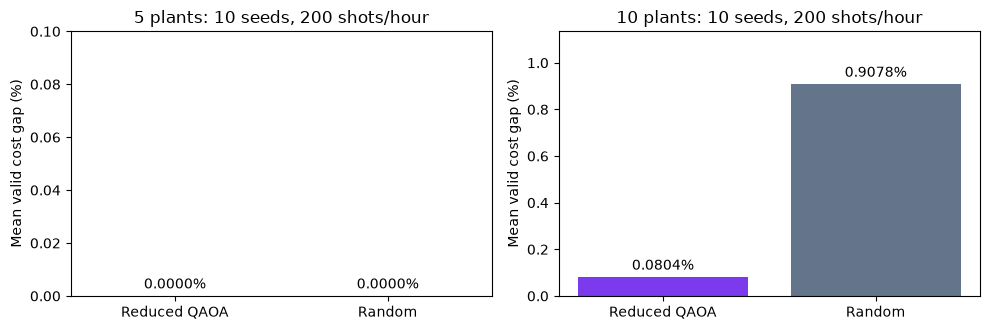

5 plants: QAOA lower/tied/higher cost = 0/10/0; 10 paired valid trials.
10 plants: QAOA lower/tied/higher cost = 9/1/0; 10 paired valid trials.


In [2]:
# Rebuild the comparison directly from saved aggregate evidence.
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
evidence = json.loads(Path('results/milestone_audit.json').read_text())
selected = [r for r in evidence['sweep_summary'] if r['shots']=='200'
            and r['method'] in ('reduced_qaoa','random_locked')]
body=''.join('<tr>'+''.join(f'<td>{v}</td>' for v in [r['fleet'],r['method'],
    f"{r['valid']}/{r['attempted']}",f"{float(r['mean_valid_gap_pct']):.4f}%",
    f"{float(r['median_total_seconds']):.3f}"] )+'</tr>' for r in selected)
display(HTML('<table><tr><th>Plants</th><th>Method</th><th>Valid</th><th>Mean gap</th><th>Median seconds</th></tr>'+body+'</table>'))
fig,axes=plt.subplots(1,2,figsize=(10,3.4))
for ax,fleet in zip(axes,(5,10)):
    rows=[next(r for r in selected if int(r['fleet'])==fleet and r['method']==method)
          for method in ('reduced_qaoa','random_locked')]
    values=[float(r['mean_valid_gap_pct']) for r in rows]
    bars=ax.bar(['Reduced QAOA','Random'],values,color=['#7c3aed','#64748b'])
    ax.bar_label(bars,labels=[f'{v:.4f}%' for v in values],padding=3)
    ax.set(title=f'{fleet} plants: 10 seeds, 200 shots/hour',ylabel='Mean valid cost gap (%)',
           ylim=(0,max(0.1,max(values)*1.25)))
fig.tight_layout();plt.show()
for r in evidence['sweep_pairs']:
    if r['shots']=='200' and r['comparator']=='random_locked':
        print(f"{r['fleet']} plants: QAOA lower/tied/higher cost = "
              f"{r['reduced_lower_gap']}/{r['ties']}/{r['reduced_higher_gap']}; "
              f"{r['common_valid']} paired valid trials.")


## Milestone 5 — simulator evidence; hardware handled separately

This is the required **original five-plant, eight-qubit, hour-14 circuit**, not a hardware demonstration of the ten-plant reduced method. Its cost phases were checked against the reproduced hourly QUBO. Three predeclared mixer-angle offsets (−0.1, 0, +0.1 radians) were evaluated on the IonQ simulator with the `forte-1` noise model, 200 shots each. Selection used only training mean encoded Ising energy. A separate 200-shot noisy readout evaluated the selected circuit; this is a small noisy parameter search, not a claim of globally optimal angles.

The selected circuit also has a matched 200-shot local ideal run. The user’s other agent is handling the real-hardware run. No QPU counts from that run have been imported here. The prepared, unsubmitted alternative was one 200-shot job on `openquantum:ionq:qpu:forte-1`, quoted at **0 qBraid credits** at audit time. The AWS route was 1,630 credits, above the user’s 500-credit budget. The chosen route has a hard zero-credit limit and requires explicit submission approval. Simulator execution is not hardware evidence, and local simulated timing is not a hardware speedup.

Noisy tuning code is preserved in [Other experiments](04_other_experiments.ipynb#milestone-noisy-tuning). The exact QASM, input hash, counts, job IDs and raw job timings are in `results/milestone_audit.json`. Raw provider duration units are retained without guessing; created-to-ended wall time includes the job lifecycle. Hardware queue/total time remain pending.


Local ideal: 200 shots; feasible 55.5%; best hourly commitment 13.0%
IonQ noisy simulator: 200 shots; feasible 49.5%; best hourly commitment 8.0%


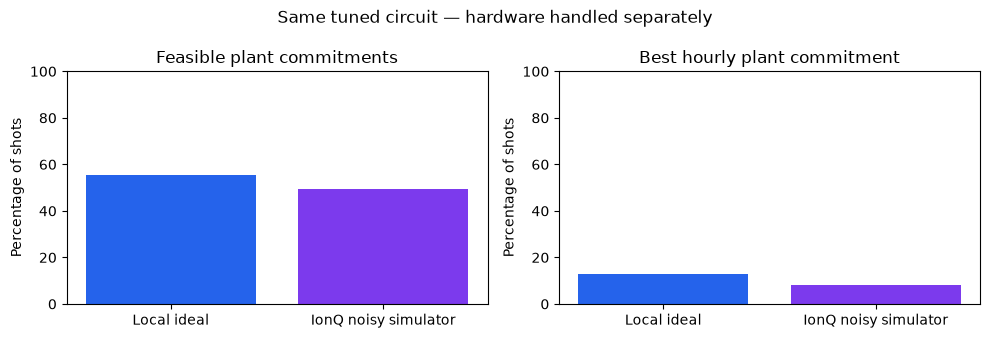

training beta shift -0.1 ionq:ionq:sim:simulator-69e6-qjob-6af97144e538ce0882fae135 cost: 0.0 credits; created-to-ended: 3.54 s
training beta shift +0.0 ionq:ionq:sim:simulator-69e6-qjob-6af97154e538ce0882fae144 cost: 0.0 credits; created-to-ended: 3.574 s
training beta shift +0.1 ionq:ionq:sim:simulator-69e6-qjob-6af97166e538ce0882fae162 cost: 0.0 credits; created-to-ended: 3.414 s
independent final noisy readout ionq:ionq:sim:simulator-69e6-qjob-6af97176e538ce0882fae16f cost: 0.0 credits; created-to-ended: 3.272 s
Hardware status: Managed separately by the user’s other agent; no QPU submitted by this agent.


In [1]:
# Offline plot: loading saved evidence does not submit or poll jobs.
import json
from pathlib import Path
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
from check import load_plants,load_demand,check_hour,hour_ok
audit = json.loads(Path('results/milestone_audit.json').read_text())
hw = audit['hardware']
assert hw['hourly_qubo_verified']
plants = load_plants(); demand,reserve=load_demand()
history=np.asarray(hw['history']);on,off=hw['must_on'],hw['must_off']
hour_check=check_hour(plants,demand[14],reserve[14],history[-1],was_on=history[-1],
                      must_on=on,must_off=off,verbose=False)
best_index=int(np.dot(hour_check['best_choice'],2**np.arange(5)))
valid=np.array([hour_ok(plants,demand[14],reserve[14],[(k>>i)&1 for i in range(5)],on,off)
                for k in range(32)])
series={'Local ideal':hw['tuned_ideal_counts'],
        'IonQ noisy simulator':hw['noise_tuning']['holdout_counts']}
if hw.get('hardware_counts'):series['IonQ QPU']=hw['hardware_counts']
shares={}
for label,counts in series.items():
    share=np.zeros(32)
    for key,count in counts.items():share[int(key.replace(' ',''),2)&31]+=count/sum(counts.values())
    shares[label]=share
    print(f'{label}: {sum(counts.values())} shots; feasible {100*share[valid].sum():.1f}%; '
          f'best hourly commitment {100*share[best_index]:.1f}%')
fig,axes=plt.subplots(1,2,figsize=(10,3.4))
axes[0].bar(list(shares),[100*v[valid].sum() for v in shares.values()],color=['#2563eb','#7c3aed','#16a34a'][:len(shares)])
axes[1].bar(list(shares),[100*v[best_index] for v in shares.values()],color=['#2563eb','#7c3aed','#16a34a'][:len(shares)])
axes[0].set(title='Feasible plant commitments',ylabel='Percentage of shots',ylim=(0,100))
axes[1].set(title='Best hourly plant commitment',ylabel='Percentage of shots',ylim=(0,100))
fig.suptitle('Same tuned circuit — hardware handled separately' if not hw.get('hardware_counts') else 'Same tuned circuit — simulator vs QPU')
fig.tight_layout();plt.show()
for row in hw['noise_tuning']['jobs']:
    stamps=row['metadata']['timeStamps']
    elapsed=(datetime.fromisoformat(stamps['endedAt'].replace('Z','+00:00'))-
             datetime.fromisoformat(stamps['createdAt'].replace('Z','+00:00'))).total_seconds()
    print(row['phase'],row['job_id'],'cost:',row['metadata'].get('cost'),
          'credits; created-to-ended:',round(elapsed,3),'s')
print('Hardware status:',hw['hardware_status'])


In [2]:
# The user’s other agent is handling hardware. Leave this disabled to avoid duplicate jobs.
# OPT-IN REAL HARDWARE ACTION. A normal Run All leaves this disabled.
# Requires explicit approval of the price and the circuit in the audit record.
APPROVE_HARDWARE_SUBMISSION = False
HARDWARE_CREDIT_LIMIT = 0.0

if APPROVE_HARDWARE_SUBMISSION:
    import subprocess,sys
    from pathlib import Path
    # Use qBraid Lab's platform SDK; the notebook SDK can predate cost estimates.
    platform_python = '/usr/bin/python'
    submission_script = r"""
import json,hashlib,sys
from pathlib import Path
from qbraid.runtime import QbraidProvider
path=Path('results/milestone_audit.json');record=json.loads(path.read_text());hw=record['hardware']
if hw.get('hardware_job_id'):raise RuntimeError('Hardware job already recorded; do not submit twice.')
program=hw['hardware_program']
assert hashlib.sha256(program.encode()).hexdigest()==hw['hardware_program_sha256']
provider=QbraidProvider();device_id=hw['hardware_device'];shots=hw['hardware_shots']
quote=provider.client.estimate_cost(device_id,shots=shots).model_dump(mode='json')
if not quote['pricingAvailable'] or float(quote['estimatedCost'])>float(sys.argv[1]):
    raise RuntimeError('Current quote is unavailable or exceeds approved credits.')
device=provider.get_device(device_id)
if 'ONLINE' not in str(device.status()):raise RuntimeError('Hardware is not online; no submission.')
job=device.run(program,shots=shots)
hw.update(hardware_job_id=job.id,hardware_status='submitted',hardware_submission_quote=quote)
path.write_text(json.dumps(record,indent=2)+'\n')
print('Submitted once:',job.id,'estimated credits:',quote['estimatedCost'])
"""
    subprocess.run([platform_python,'-c',submission_script,str(HARDWARE_CREDIT_LIMIT)],check=True)
else:
    print('No hardware submitted here. The user’s other agent is handling milestone 5.')


No hardware submitted here. The user’s other agent is handling milestone 5.


In [5]:
# Optional READ-ONLY refresh after a job ID exists; this never submits a job.
REFRESH_HARDWARE_RESULT = False
if REFRESH_HARDWARE_RESULT:
    import subprocess
    refresh_script = r"""
import json
from pathlib import Path
from qbraid.runtime import QbraidProvider
path=Path('results/milestone_audit.json');record=json.loads(path.read_text());hw=record['hardware']
job_id=hw.get('hardware_job_id')
if not job_id:raise RuntimeError('No hardware job has been submitted.')
p=QbraidProvider();job=p.client.get_job(job_id).model_dump(mode='json')
hw['hardware_metadata']=job;hw['hardware_status']=str(job['status'])
if hw['hardware_status']=='COMPLETED':
    result=p.client.get_job_result(job_id).model_dump(mode='json')
    hw['hardware_result']=result
    hw['hardware_counts']=result['resultData']['measurementCounts']
path.write_text(json.dumps(record,indent=2)+'\n')
print(job_id,hw['hardware_status'])
"""
    subprocess.run(['/usr/bin/python','-c',refresh_script],check=True)
    print('Rerun the offline hardware-report cell to include completed QPU counts.')


<a id="warm-start-hardware-comparison"></a>
## Selected hardware method — warm-start Reduced Qubit Hybrid Hourly

**The five- and ten-plant hardware comparison uses the warm-start variant.** The RQ 1–RQ 5 study uses the original reduced-hourly protocol.

The warm-start method first removes only legally forced plant decisions. A cheap classical merit-order heuristic then supplies a feasible hourly starting row. Free plant bits are biased toward that row, and QAOA uses nonzero cost evolution and a mixer matched to the initial state. The cheapest feasible candidate must appear in the fresh final measurements; the starting row is never silently substituted for a hardware result.

Use gross demand, no solar/wind, p=1, hours 13–17, six angle candidates with 256 simulation training shots each, and 200 fresh final shots per hour. For hardware, train the angles in simulation for the current history, then execute the chosen circuit on the QPU. Compare hardware and ideal simulation on identical circuits and shot counts; keep any full-day trajectories separately identified. The existing initial MILP and conditional tail MILP remain part of the hybrid.

**Simulation finding:** Warm-started reduced-qubit QAOA achieved a valid 100-plant schedule within **0.059% of the MILP optimum** in simulation; classical controls matched or improved this result.

The setup below exposes the existing warm-start implementation without submitting jobs. The final cell displays **saved local Aer MPS simulation results**, not hardware measurements or a new run. Completed QPU results are shown in the hardware section below.


In [ ]:
# SELECTED METHOD: warm-start Reduced Qubit Hybrid Hourly, 5 and 10 plants.
# Setup/helpers only: no simulator jobs, hardware submissions, or paid actions.
from pathlib import Path
import sys

warm_candidates = [Path.cwd(), Path.cwd() / '3-tva-plant-scheduling',
                   Path.cwd().parent / '3-tva-plant-scheduling']
warm_method_dir = next(p for p in warm_candidates if (p / 'warm_start_scaling.py').exists())
if str(warm_method_dir) not in sys.path:
    sys.path.insert(0, str(warm_method_dir))
import warm_start_scaling as warm_hourly

WARM_START_HARDWARE_METHOD = 'warm_start_reduced_qubit_hybrid_hourly'
WARM_START_FLEETS = (5, 10)
WARM_START_HOURS = tuple(range(13, 18))
WARM_START_TRAINING_SHOTS = warm_hourly.TRAIN_SHOTS  # 256 per angle, simulation
WARM_START_FINAL_SHOTS = warm_hourly.FINAL_SHOTS    # 200 fresh shots per hour

def prepare_warm_start_training(namespace, hour, history):
    """Build the six warm-start training circuits from this actual history."""
    if namespace['N'] not in WARM_START_FLEETS or hour not in WARM_START_HOURS:
        raise ValueError('This hardware comparison is configured for 5/10 plants and hours 13–17.')
    trace = warm_hourly.layout(namespace, hour, history)
    return {'trace': trace, 'angles': list(warm_hourly.ANGLES),
            'circuits': [warm_hourly.from_trace(trace, a) for a in warm_hourly.ANGLES]}

def select_warm_start_circuit(namespace, prepared, simulation_training_counts):
    """Choose angles by the existing feasibility/cost rule before final sampling."""
    if len(simulation_training_counts) != len(prepared['angles']):
        raise ValueError('Supply one simulated training-count dictionary per angle.')
    if any(sum(counts.values()) != WARM_START_TRAINING_SHOTS
           for counts in simulation_training_counts):
        raise ValueError('Every training circuit must use 256 shots.')
    scores = [warm_hourly.summarize(counts, prepared['trace'], namespace)
              for counts in simulation_training_counts]
    index = warm_hourly.ft.choose(scores)
    return {'trace': prepared['trace'], 'chosen_index': index,
            'angles': prepared['angles'][index], 'training_scores': scores,
            'circuit': warm_hourly.from_trace(prepared['trace'], prepared['angles'][index])}

def evaluate_warm_start_final_counts(namespace, selected, fresh_counts):
    """Score fresh ideal or QPU counts; no repair or substitution of the seed."""
    if sum(fresh_counts.values()) != WARM_START_FINAL_SHOTS:
        raise ValueError('Supply the separate 200-shot final measurement batch.')
    # Expected convention: classical bit 0 is the RIGHTMOST character.
    # The hardware adapter must verify/normalize its provider's bit ordering.
    return warm_hourly.summarize(fresh_counts, selected['trace'], namespace)

print('Selected warm-start method for fleets', WARM_START_FLEETS,
      '| quantum hours', WARM_START_HOURS, '| final shots', WARM_START_FINAL_SHOTS)
print('No jobs submitted. Saved simulation results follow below.')


| Plants | Valid full day | Warm QAOA gap | Qubits | Classical local-search gap |
|---:|:---:|---:|---:|---:|
| 5 | True | 0.0000% | 7–8 | 0.0000% |
| 10 | True | 0.0101% | 11–12 | 0.0101% |
| 25 | True | 0.0853% | 21–26 | 0.0853% |
| 50 | True | 0.0828% | 39–50 | 0.0751% |
| 100 | True | 0.0590% | 69–99 | 0.0529% |

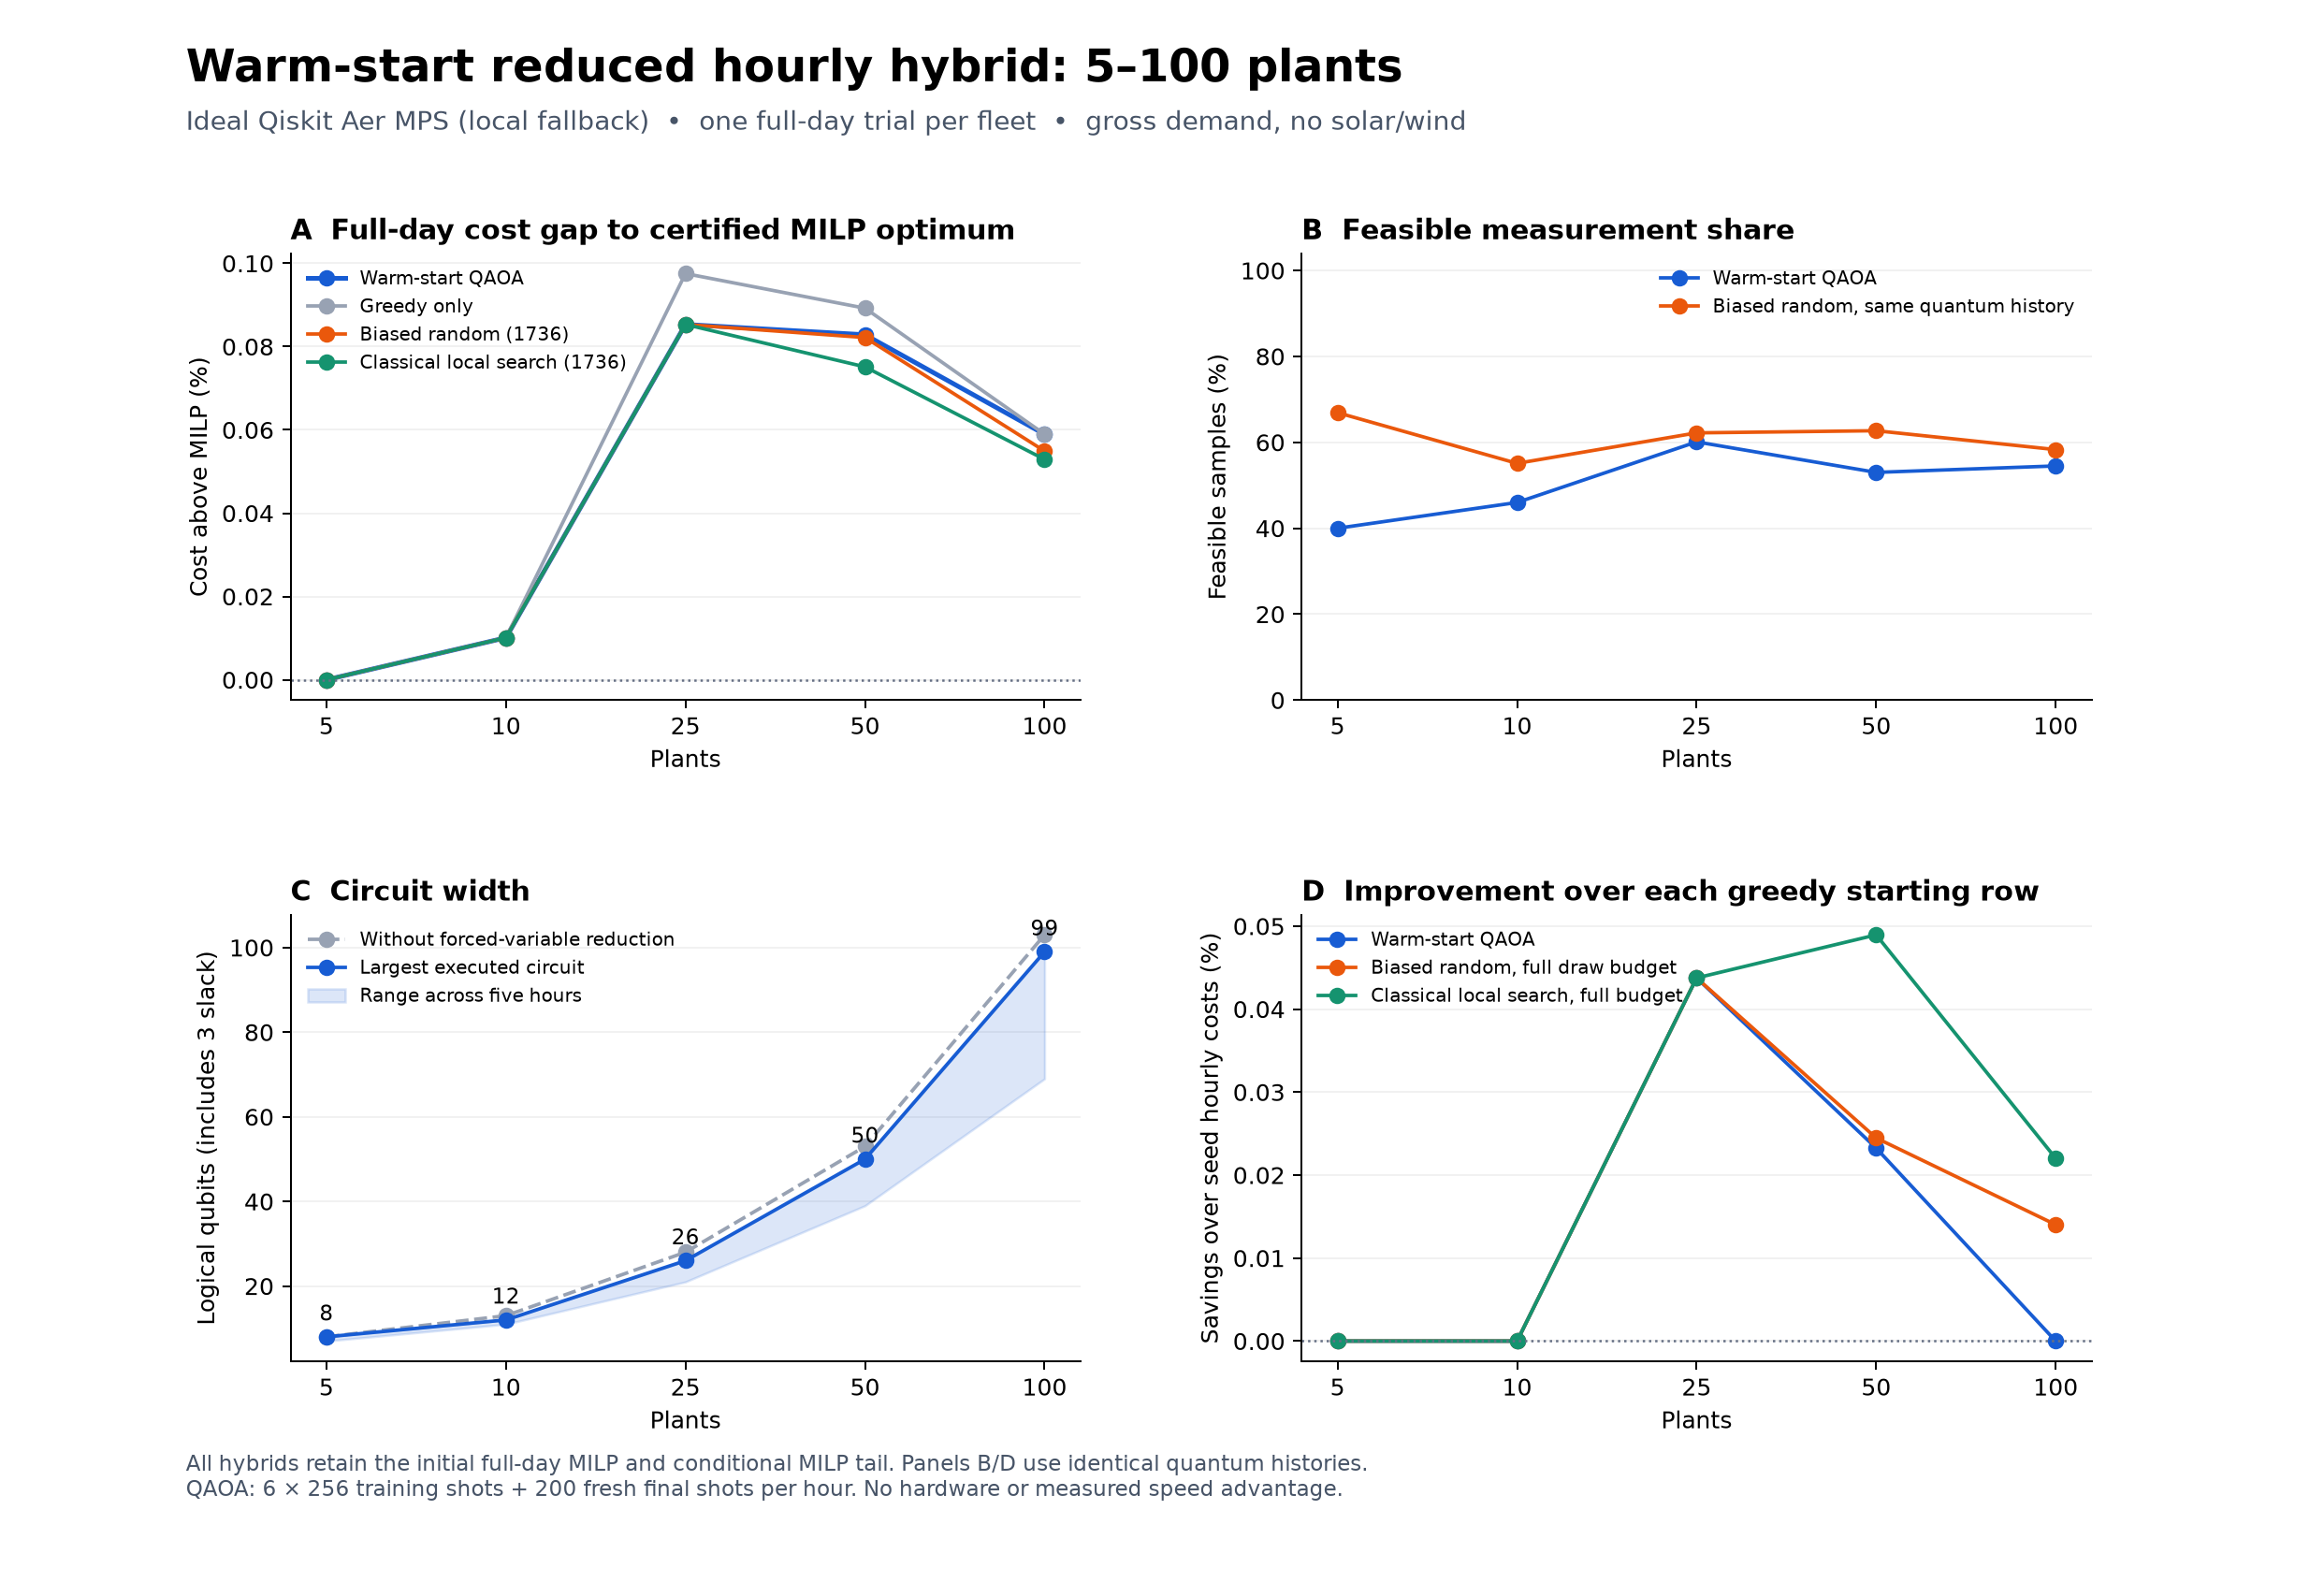

**One trajectory per fleet.** The greedy warm start uses no optimal hourly answer. The hybrid still uses an initial full-day MILP and a conditional tail MILP. Fresh quantum measurement candidates are compared against classical controls; this is not evidence of a runtime advantage. See [full report](results/warm_start_scaling/20261115T083253067634Z/REPORT.md) for budgets, costs, and validation.

In [1]:
# Read saved results only. This cell does NOT submit simulator or hardware jobs.
from pathlib import Path
import json
from IPython.display import display, Markdown, Image

warm_start_result_dir = Path('results/warm_start_scaling/20261115T083253067634Z')
warm_start_results = json.loads((warm_start_result_dir / "pilot.json").read_text())
lines = ["| Plants | Valid full day | Warm QAOA gap | Qubits | Classical local-search gap |",
         "|---:|:---:|---:|---:|---:|"]
for fleet, run in warm_start_results["fleets"].items():
    quantum = run["quantum"]
    widths = [row["reduced_qubits"] for row in quantum["hourly"]]
    gap = quantum.get("checked", {}).get("gap_pct")
    classical_gap = run["controls"]["local_search"].get("checked", {}).get("gap_pct")
    gap_text = "failed" if gap is None else f"{gap:.4f}%"
    classical_text = "failed" if classical_gap is None else f"{classical_gap:.4f}%"
    lines.append(f"| {fleet} | {quantum['valid']} | {gap_text} | {min(widths)}–{max(widths)} | {classical_text} |")
display(Markdown("\n".join(lines)))
display(Image(filename=str(warm_start_result_dir / "warm_start_scaling.png")))
display(Markdown("**One trajectory per fleet.** The greedy warm start uses no optimal hourly answer. "
                 "The hybrid still uses an initial full-day MILP and a conditional tail MILP. "
                 "Fresh quantum measurement candidates are compared against classical controls; "
                 "this is not evidence of a runtime advantage. See [full report](" +
                 str(warm_start_result_dir / "REPORT.md") + ") for budgets, costs, and validation."))

# Explicit optional local rerun (no cloud or hardware submission):
# from warm_start_local_mps import main as run_warm_start_scaling
# new_results = run_warm_start_scaling(fleets=(5, 10, 25, 50, 100))


## Warm-start hardware results — saved comparison

The five- and ten-plant experiments completed on Rigetti Cepheus through AWS: five quantum hours per fleet, 200 final shots per hour, 10 jobs total. Both full-day schedules passed the checker. Hardware cost gaps were 0% for five plants and 1.5265% for ten plants.

This viewer reads saved results and does not submit jobs. These are warm-start hardware results; the original reduced-hourly simulation remains a separate experiment.


| Plants | Ideal daily gap | Hardware status | Hardware daily gap | Feasible hardware shots |
|---:|---:|:---|---:|---:|
| 5 | 0.0000% | COMPLETED | 0.0000% | 251/1000 |
| 10 | 0.0101% | COMPLETED | 1.5265% | 118/1000 |

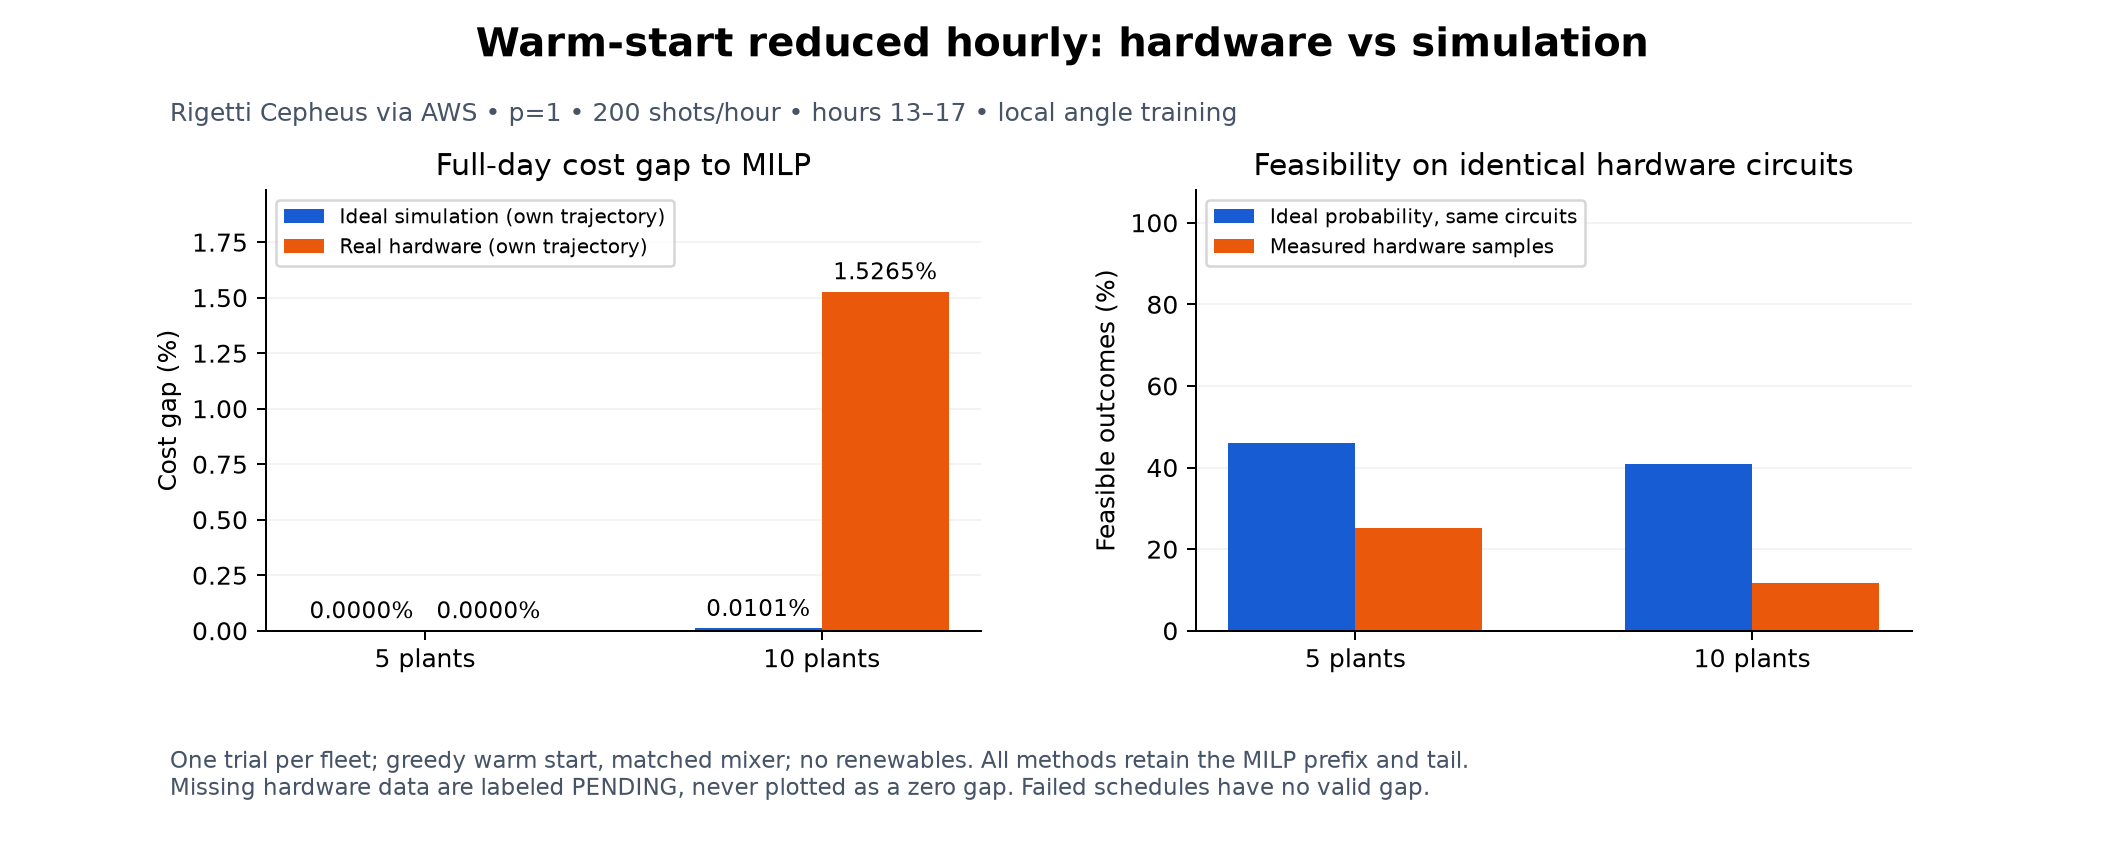

[Full warm-start hardware report](results/warm_start_hardware/20261115T085833206497Z/REPORT.md)

In [1]:
# READ-ONLY: display the existing selected warm-start run. No job submission.
from pathlib import Path
import json
from IPython.display import display, Markdown, Image

HARDWARE_RESULTS_DIR = Path('results/warm_start_hardware/20261115T085833206497Z')
hardware_hourly_results = json.loads((HARDWARE_RESULTS_DIR / "experiment.json").read_text())
comparison_lines = ["| Plants | Ideal daily gap | Hardware status | Hardware daily gap | Feasible hardware shots |",
                    "|---:|---:|:---|---:|---:|"]
for fleet, item in hardware_hourly_results["fleets"].items():
    hardware = item["hardware"]
    finished = [row for row in hardware["hourly"] if "hardware" in row]
    hardware_gap = hardware.get("checked", {}).get("gap_pct")
    hardware_gap_text = "pending" if hardware_gap is None else f"{hardware_gap:.4f}%"
    if hardware["status"] == "FAILED": hardware_gap_text = "failed — no valid gap"
    feasible = sum(row["hardware"]["valid_shots"] for row in finished)
    total = sum(row["hardware"]["shots"] for row in finished)
    ideal_gap = item["simulation"]["checked"]["gap_pct"]
    comparison_lines.append(f"| {fleet} | {ideal_gap:.4f}% | {hardware['status']} | {hardware_gap_text} | {feasible}/{total} |")
display(Markdown("\n".join(comparison_lines)))
display(Image(filename=str(HARDWARE_RESULTS_DIR / "hardware_vs_simulation.png")))
display(Markdown("[Full warm-start hardware report](" + str(HARDWARE_RESULTS_DIR / "REPORT.md") + ")"))


## Real QPU results — warm-start 5- and 10-plant comparison

Device: **Rigetti Cepheus-1-108Q through Amazon Braket**, accessed with qBraid. This section uses the selected greedy warm start and aligned mixer, not the older original-QAOA milestone circuit. Angles are trained locally on six candidates (256 simulated shots each); the selected circuit receives 200 fresh **physical QPU shots** per hour. Hours 13–17 adapt to the preceding measured choices. Gross demand only; no solar/wind.

The first bar chart compares full-day cost gaps for independently evolving simulation and hardware schedules. The second uses the **identical hardware circuits and histories**, comparing their ideal feasible probabilities with measured hardware outcomes. Both hybrids retain the MILP prefix and tail. One trial per fleet is a hardware demonstration, not a reliability study or quantum-advantage claim.

The following cell only reads saved results and draws the chart; it cannot submit another job.


| Plants | Simulation gap | Hardware status | Hardware gap | Feasible QPU shots |
|---:|---:|:---|---:|---:|
| 5 | 0.0000% | COMPLETED | 0.0000% | 251/1000 |
| 10 | 0.0101% | COMPLETED | 1.5265% | 118/1000 |

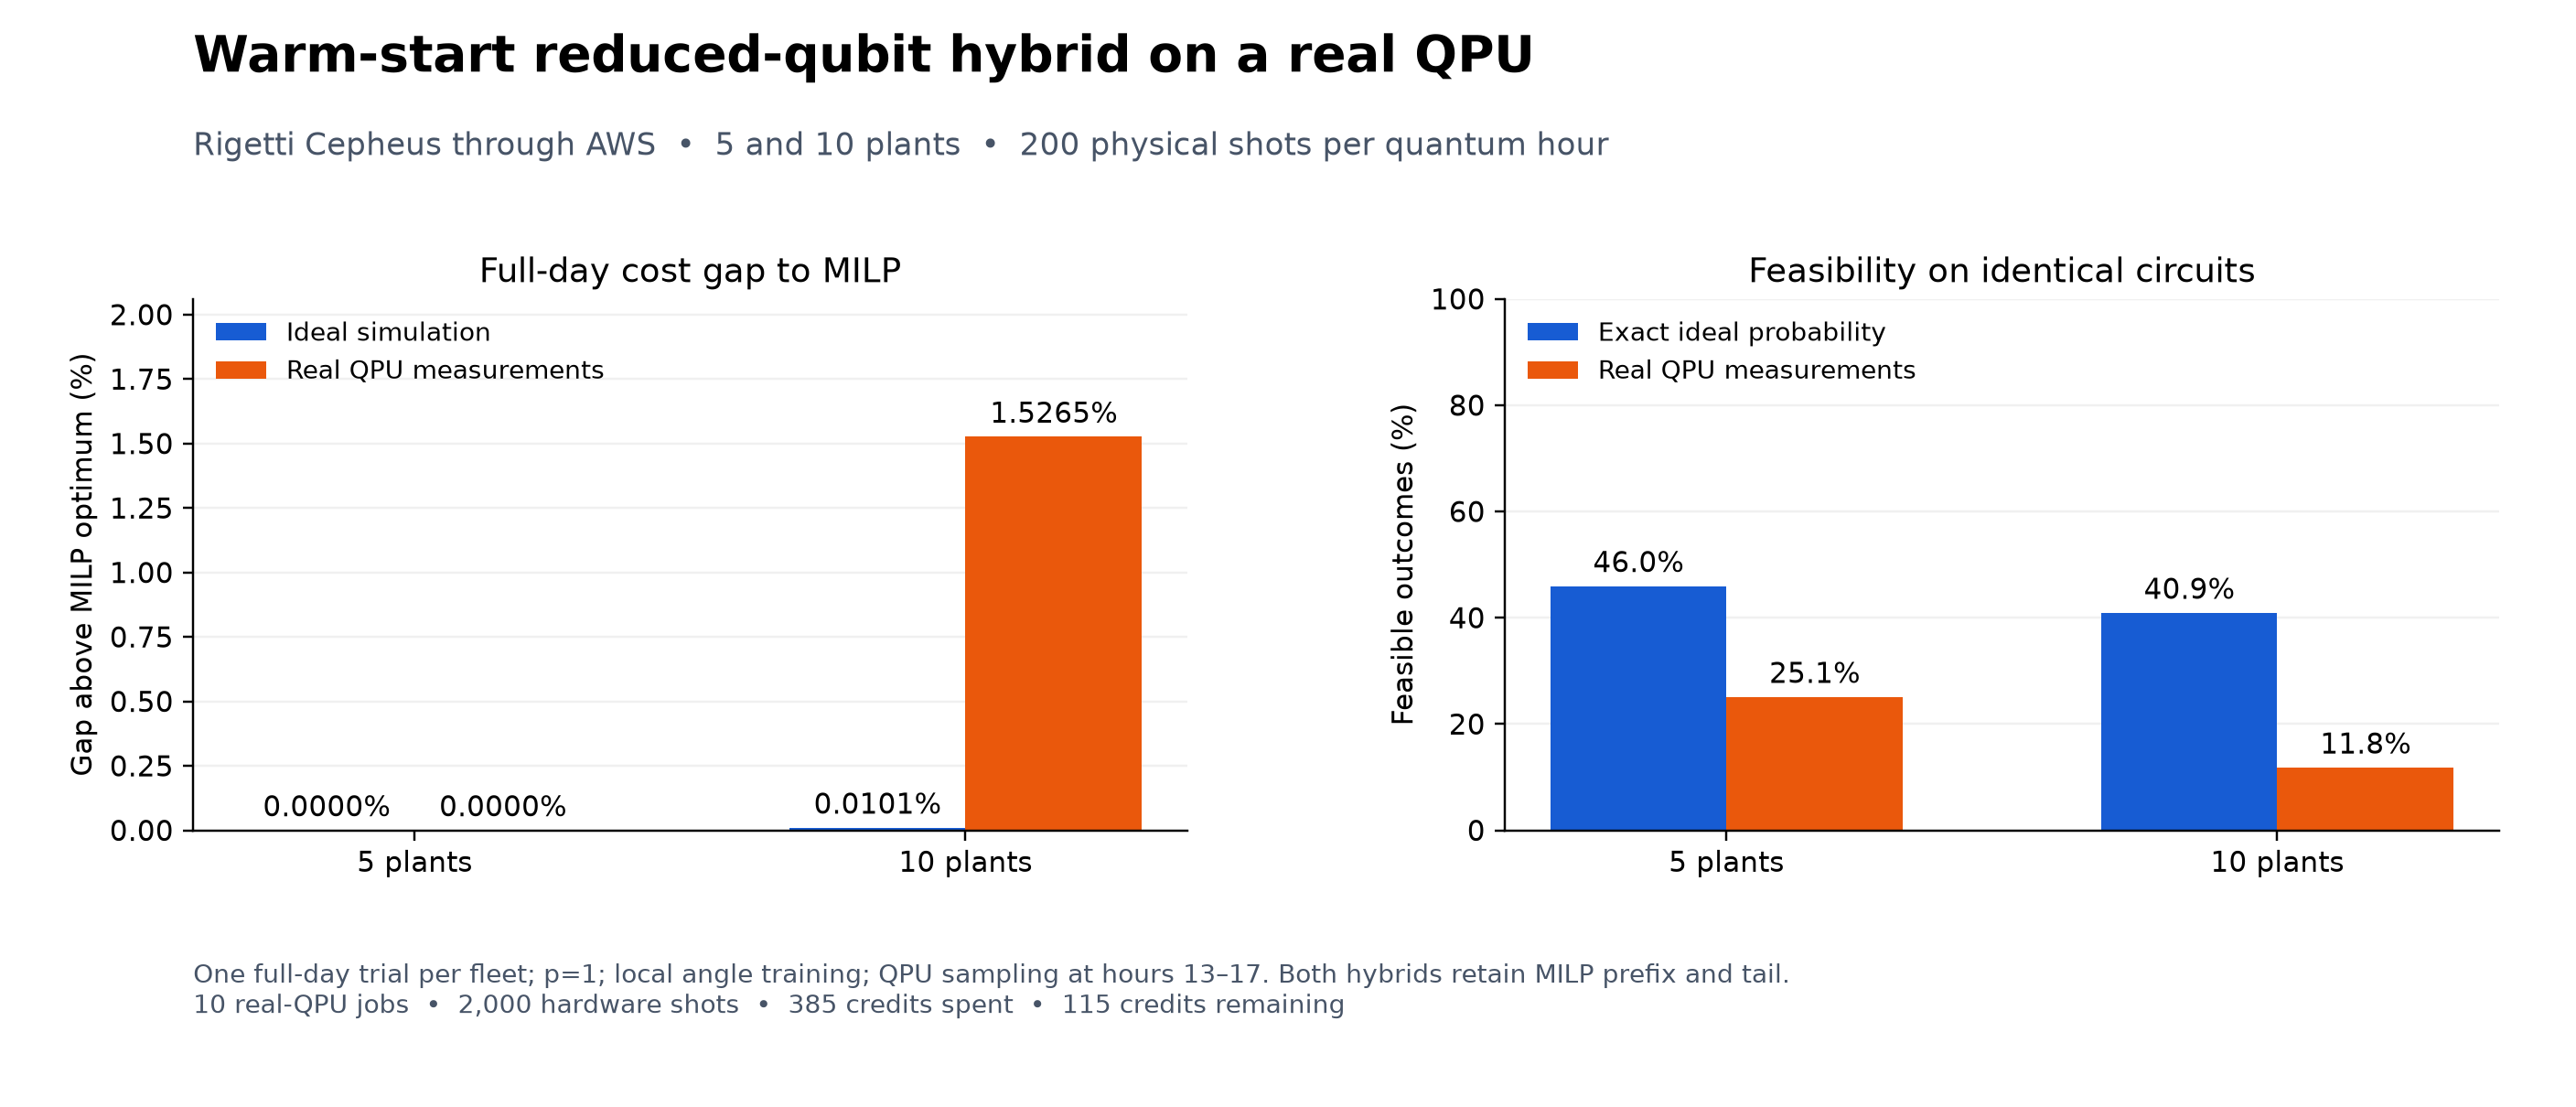

**Real device:** `aws:rigetti:qpu:cepheus-1-108q`

**QPU job IDs:**

- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af9748be538ce0882fae20e` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af974c4e538ce0882fae21f` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af974dfe538ce0882fae22d` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af97519e538ce0882fae28b` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af97552e538ce0882fae2a1` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af9758ce538ce0882fae2b7` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af975c5e538ce0882fae2c4` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af975ffe538ce0882fae2d5` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af97638e538ce0882fae2e4` — COMPLETED
- `aws:rigetti:qpu:cepheus-1-108q-69e6-qjob-6af97654e538ce0882fae2f3` — COMPLETED

In [1]:
# READ-ONLY: saved real-QPU results; no submissions or paid actions.
from pathlib import Path
import json
from IPython.display import display, Markdown, Image
warm_hardware_result_dir = Path('results/warm_start_hardware/20261115T085833206497Z')
warm_hardware_results = json.loads((warm_hardware_result_dir / 'experiment.json').read_text())
lines = ['| Plants | Simulation gap | Hardware status | Hardware gap | Feasible QPU shots |',
         '|---:|---:|:---|---:|---:|']
for fleet, run in warm_hardware_results['fleets'].items():
    hw = run['hardware']; done = [t for t in hw['hourly'] if 'hardware' in t]
    gap = hw.get('checked', {}).get('gap_pct')
    gap_text = '—' if gap is None else f'{gap:.4f}%'
    lines.append(f"| {fleet} | {run['simulation']['checked']['gap_pct']:.4f}% | {hw['status']} | {gap_text} | "
                 f"{sum(t['hardware']['valid_shots'] for t in done)}/{len(done)*200} |")
display(Markdown('\n'.join(lines)))
display(Image(filename=str(warm_hardware_result_dir / 'hardware_vs_simulation.png')))
display(Markdown('**Real device:** `' + warm_hardware_results['device'] + '`\n\n' +
    '**QPU job IDs:**\n\n' + '\n'.join('- `' + j['job_id'] + '` — ' + j['status'] for j in warm_hardware_results['jobs'])))
